# Check-in 3: Graph WaveNet vs the CI2 GRU

This notebook doesn't train or run any model. It loads saved test-set predictions and compares them on the same 6,832 test windows:
* the CI2 GRU, persistence and historical average come from CI2's own file, `../Project_check_in_2/runs/gru_h64/test_preds.npz`;
* the two Graph WaveNet runs (`gwnet_full` and `gwnet_nograph`) come from `runs/<run>/test_preds.npz`, written by `python -m src.evaluate`.

The analysis code is the CI2 notebook's code with more models added, so the CI2 and CI3 numbers come from the same functions. Figures go to `figures/`, and every number quoted in [`check-in-3.md`](../check-in-3.md) is also saved to `figures/ci3_numbers.json`.

In [1]:
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.config import data_paths, FIG_DIR, RUNS_DIR
from src.data import load_processed, load_adj, load_locations
from src.evaluate import results_table, to_markdown
from src.metrics import horizon_report

warnings.filterwarnings("ignore", "Mean of empty slice")
warnings.filterwarnings("ignore", "All-NaN slice")
FULL_RUN = "gwnet_full"
NOGRAPH_RUN = "gwnet_nograph"
CI2 = ROOT.parent / "Project_check_in_2"
GRU_RUN = CI2 / "runs" / "gru_h64"

paths = data_paths()
arrays, meta = load_processed(paths["processed"])
_, _, adj = load_adj(paths["adj"], sensor_ids=meta["sensor_ids"])
locations = load_locations(paths["locations"])

# CI2 file: targets, baselines and the GRU predictions
with np.load(GRU_RUN / "test_preds.npz") as z:
    y = z["y"]
    preds = {"Persistence": z["persistence"], "HA": z["ha"], "GRU": z["gru"]}
    target_idx, x_missing = z["target_index"], z["x_missing_frac"]

# CI3 runs: must be on exactly the same windows and targets
for name, run_name in [("GWN no-graph", NOGRAPH_RUN), ("GWN full", FULL_RUN)]:
    with np.load(RUNS_DIR / run_name / "test_preds.npz") as z:
        assert np.array_equal(z["y"], y), f"{run_name}: targets differ from CI2"
        assert np.array_equal(z["target_index"], target_idx), f"{run_name}: windows differ from CI2"
        preds[name] = z["pred"]

# the GRU numbers we compute here must be the ones CI2 reported
ci2_metrics = json.loads((GRU_RUN / "test_metrics.json").read_text())
ours = horizon_report(preds["GRU"], y)
for h in ["15 min", "30 min", "60 min"]:
    for m in ["MAE", "RMSE", "MAPE (%)"]:
        assert abs(ours[h][m] - ci2_metrics[h][m]) < 1e-6, (h, m)
print("same test windows and targets for all models; GRU metrics match CI2's test_metrics.json")

ts = pd.DatetimeIndex(pd.to_datetime(arrays["timestamps"]))
raw, sensor_ids = arrays["raw"], np.array(meta["sensor_ids"])
s_te, e_te = meta["splits"]["test"]
obs = y != 0
err = {k: np.abs(p - y) for k, p in preds.items()}
MODELS = list(preds)
NEURAL = ["GRU", "GWN no-graph", "GWN full"]
HORIZONS = ["15 min", "30 min", "60 min"]
numbers = {}   # every number quoted in check-in-3.md
print(f"test windows {y.shape[0]:,} x horizons {y.shape[1]} x sensors {y.shape[2]}; observed targets {obs.mean():.1%}")

fig_dir = FIG_DIR
fig_dir.mkdir(exist_ok=True)
# CI2 colours for the CI2 models; both Graph WaveNet runs are purple and differ by line style
C1, C2, C3, C4, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#7b3fbf", "#8a8984"
COL = {"GRU": C1, "Persistence": C2, "HA": C3, "GWN full": C4, "GWN no-graph": C4, "truth": "#222222"}
LS = {"GRU": "-", "Persistence": "-", "HA": "-", "GWN full": "-", "GWN no-graph": "--"}
HATCH = {"GWN no-graph": "///"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
                     "lines.linewidth": 1.5})

def save(fig, name):
    fig.savefig(fig_dir / f"{name}.png")
    plt.show()

def mae(k, sel):
    # MAE of model k over the cells selected by sel (missing targets are skipped)
    sel = sel & obs
    return float(err[k][sel].mean())

def bars(ax, table, models, width=None):
    # grouped bars, one group per row of table; the no-graph model is hatched so it reads without colour
    width = width or 0.8 / len(models)
    xs = np.arange(len(table))
    for i, k in enumerate(models):
        ax.bar(xs + (i - (len(models) - 1) / 2) * width, table[k], width, color=COL[k], label=k,
               hatch=HATCH.get(k), edgecolor="white", alpha=0.6 if k in HATCH else 1)
    ax.set_xticks(xs)
    ax.set_xticklabels(table.index)

same test windows and targets for all models; GRU metrics match CI2's test_metrics.json
test windows 6,832 x horizons 12 x sensors 207; observed targets 87.9%


## 1. Training runs and cost
The three neural models were trained with the same data, loss, optimizer, batch size, LR schedule, early stopping rule and seed. The table lists what each run used and what it cost. Inference time is for all 6,832 test windows on the same machine.

,parameters,max epochs,epochs trained,best epoch,best val MAE,sec / epoch,train time (min),inference (s),final lr,LR cuts
model,,,,,,,,,,
GRU,51340,40,40,40,3.249,27.323,18.217,3.841,0.0,2
GWN no-graph,247724,48,48,41,3.234,65.786,52.639,4.851,0.0,4
GWN full,301016,48,36,28,2.781,117.543,70.533,10.673,0.0,2


,GRU,GWN no-graph,GWN full
use_mask,True,True,True
lr,0.001,0.001,0.001
weight_decay,0.0001,0.0001,0.0001
batch_size,64,64,64
clip,5.0,5.0,5.0
lr_factor,0.5,0.5,0.5
lr_patience,3,3,3
es_patience,8,8,8
seed,42,42,42
dropout,0.1,0.3,0.3


identical across the three runs: use_mask, lr, weight_decay, batch_size, clip, lr_factor, lr_patience, es_patience, seed


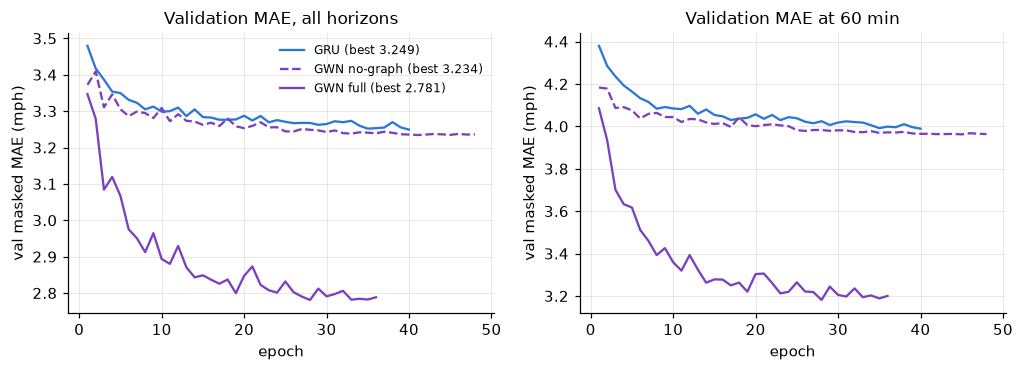

In [2]:
RUN_DIRS = {"GRU": GRU_RUN, "GWN no-graph": RUNS_DIR / NOGRAPH_RUN, "GWN full": RUNS_DIR / FULL_RUN}
# inference was timed with CI3's evaluate.py for all three models (the GRU re-check lives in runs/gru_h64_ci2_recheck)
TIMING_DIRS = {**RUN_DIRS, "GRU": RUNS_DIR / "gru_h64_ci2_recheck"}
cfgs, summs, hists = {}, {}, {}
rows = []
for k in NEURAL:
    cfgs[k] = json.loads((RUN_DIRS[k] / "config.json").read_text())
    summs[k] = json.loads((RUN_DIRS[k] / "summary.json").read_text())
    hists[k] = pd.read_csv(RUN_DIRS[k] / "metrics.csv")
    inference = json.loads((TIMING_DIRS[k] / "test_metrics.json").read_text())["inference_sec"]
    rows.append({
        "model": k,
        "parameters": summs[k]["n_params"],
        "max epochs": cfgs[k]["max_epochs"],
        "epochs trained": summs[k]["epochs_trained"],
        "best epoch": summs[k]["best_epoch"],
        "best val MAE": summs[k]["best_val_mae"],
        "sec / epoch": hists[k].epoch_sec.mean(),
        "train time (min)": summs[k]["wall_clock_min"],
        "inference (s)": inference,
        "final lr": hists[k].lr.iloc[-1],
        "LR cuts": int((hists[k].lr.diff() < 0).sum()),
    })
cost = pd.DataFrame(rows).set_index("model")
display(cost.round(3))
cost.round(3).to_csv(fig_dir / "cost.csv")
numbers["cost"] = cost.round(3).reset_index().to_dict("records")

# settings that must be identical across the three runs
same_keys = ["use_mask", "lr", "weight_decay", "batch_size", "clip", "lr_factor", "lr_patience", "es_patience", "seed"]
settings = pd.DataFrame({k: {key: cfgs[k][key] for key in same_keys + ["dropout", "max_epochs"]} for k in NEURAL})
settings.loc["graph_mode"] = ["-", cfgs["GWN no-graph"]["graph_mode"], cfgs["GWN full"]["graph_mode"]]
display(settings)
for key in same_keys:
    assert len({str(cfgs[k][key]) for k in NEURAL}) == 1, f"{key} differs between runs"
print("identical across the three runs:", ", ".join(same_keys))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for k in NEURAL:
    ax[0].plot(hists[k].epoch, hists[k].val_mae, LS[k], color=COL[k], label=f"{k} (best {summs[k]['best_val_mae']:.3f})")
    ax[1].plot(hists[k].epoch, hists[k].val_mae_60, LS[k], color=COL[k], label=k)
ax[0].set(xlabel="epoch", ylabel="val masked MAE (mph)", title="Validation MAE, all horizons")
ax[1].set(xlabel="epoch", ylabel="val masked MAE (mph)", title="Validation MAE at 60 min")
ax[0].legend(fontsize=8)
save(fig, "R0_learning_curves")

**Takeaway.** The three runs share every training setting except the two we list as differences: dropout (0.1 for the GRU, 0.3 for Graph WaveNet, the paper's value) and the epoch cap (40 vs 48). GWN full stopped early at epoch 36 (best epoch 28, val MAE 2.781), while the no-graph model used all 48 epochs and still ended at 3.234, right next to the GRU's 3.249. The graph is what costs time: GWN full needs 117.5 s per epoch against 65.8 s without the graph and 27.3 s for the GRU, because every layer multiplies the 207-sensor feature map by three adjacency matrices twice.

## 2. Test results at 15 / 30 / 60 min
All five models are scored on the same windows with the same masked metrics (`results_table` from `src/evaluate.py`).

In [3]:
res = results_table({k: preds[k] for k in MODELS}, y)
display(res.round(2))
res.round(2).to_csv(fig_dir / "results_table.csv")
(fig_dir / "results_table.md").write_text(to_markdown(res))
numbers["results"] = {m: {f"{h} {k}": round(float(v), 2) for (h, k), v in r.items()} for m, r in res.iterrows()}

# GWN full minus GRU: negative means Graph WaveNet is better
delta = pd.DataFrame({
    "GWN full - GRU": res.loc["GWN full"] - res.loc["GRU"],
    "% change": 100 * (res.loc["GWN full"] / res.loc["GRU"] - 1),
    "GWN no-graph - GRU": res.loc["GWN no-graph"] - res.loc["GRU"],
    "GWN full - GWN no-graph": res.loc["GWN full"] - res.loc["GWN no-graph"],
})
display(delta.round(3))
numbers["delta_15_30_60"] = {f"{h} {m}": {c: round(float(delta.loc[(h, m), c]), 3) for c in delta.columns} for h, m in delta.index}
for h in HORIZONS:
    best_base = min(res.loc["Persistence", (h, "MAE")], res.loc["HA", (h, "MAE")])
    print(f"{h}: GWN full MAE {res.loc['GWN full', (h, 'MAE')]:.2f}, GRU {res.loc['GRU', (h, 'MAE')]:.2f}, best baseline {best_base:.2f}")

horizon      15 min                30 min                60 min         \
metric          MAE  RMSE MAPE (%)    MAE  RMSE MAPE (%)    MAE   RMSE   
model                                                                    
Persistence    3.71  7.47     8.94   4.62  9.64    11.48   6.14  12.61   
HA             4.19  7.86    13.06   4.19  7.86    13.06   4.19   7.86   
GRU            2.99  5.89     8.03   3.60  7.28    10.32   4.46   8.95   
GWN no-graph   2.98  5.91     7.92   3.58  7.30    10.22   4.44   8.98   
GWN full       2.70  5.16     7.06   3.07  6.18     8.46   3.48   7.23   

horizon                
metric       MAPE (%)  
model                  
Persistence     15.69  
HA              13.06  
GRU             13.76  
GWN no-graph    13.71  
GWN full         9.99

GWN full - GRU  % change  GWN no-graph - GRU  \
horizon metric                                                   
15 min  MAE               -0.298    -9.941              -0.012   
        RMSE              -0.735   -12.475               0.017   
        MAPE (%)          -0.973   -12.118              -0.113   
30 min  MAE               -0.530   -14.729              -0.015   
        RMSE              -1.099   -15.101               0.023   
        MAPE (%)          -1.861   -18.027              -0.105   
60 min  MAE               -0.985   -22.050              -0.027   
        RMSE              -1.715   -19.167               0.027   
        MAPE (%)          -3.768   -27.384              -0.045   

                  GWN full - GWN no-graph  
horizon metric                             
15 min  MAE                        -0.286  
        RMSE                       -0.752  
        MAPE (%)                   -0.860  
30 min  MAE                        -0.515  
        RMSE                       -1.122  
        MAPE (%)                   -1.757  
60 min  MAE                        -0.958  
        RMSE                       -1.742  
        MAPE (%)                   -3.722

15 min: GWN full MAE 2.70, GRU 2.99, best baseline 3.71
30 min: GWN full MAE 3.07, GRU 3.60, best baseline 4.19
60 min: GWN full MAE 3.48, GRU 4.46, best baseline 4.19


Published numbers, for reference only. Both papers cut windows before splitting and use their own preprocessing (see CI1 §4), so the protocol differs slightly from ours and the rows are not directly comparable. The values are the ones reported in Wu et al. 2019, Table 2.

In [4]:
published = pd.DataFrame(
    {"DCRNN (Li et al. 2018)": [2.77, 5.38, 7.30, 3.15, 6.45, 8.80, 3.60, 7.60, 10.50],
     "Graph WaveNet (Wu et al. 2019)": [2.69, 5.15, 6.90, 3.07, 6.22, 8.37, 3.53, 7.37, 10.01]},
    index=res.columns).T
published.index.name = "published (protocol differs)"
display(published)
published.to_csv(fig_dir / "published_reference.csv")
gap = res.loc["GWN full"].xs("MAE", level="metric") - published.loc["Graph WaveNet (Wu et al. 2019)"].xs("MAE", level="metric")
print("our GWN full MAE minus the published Graph WaveNet MAE:", gap.round(2).to_dict())
numbers["gap_to_published_gwn_mae"] = gap.round(2).to_dict()

horizon                        15 min                30 min                 \
metric                            MAE  RMSE MAPE (%)    MAE  RMSE MAPE (%)   
published (protocol differs)                                                 
DCRNN (Li et al. 2018)           2.77  5.38      7.3   3.15  6.45     8.80   
Graph WaveNet (Wu et al. 2019)   2.69  5.15      6.9   3.07  6.22     8.37   

horizon                        60 min                 
metric                            MAE  RMSE MAPE (%)  
published (protocol differs)                          
DCRNN (Li et al. 2018)           3.60  7.60    10.50  
Graph WaveNet (Wu et al. 2019)   3.53  7.37    10.01

our GWN full MAE minus the published Graph WaveNet MAE: {'15 min': 0.01, '30 min': -0.0, '60 min': -0.05}


**Takeaway.** GWN full beats the GRU on every metric at every horizon: MAE falls by 0.30 / 0.53 / 0.99 mph at 15 / 30 / 60 min (10% / 15% / 22%). GWN no-graph is within 0.03 mph of the GRU everywhere, and its RMSE is slightly worse (+0.02 to +0.03), so the deeper convolutional architecture on its own buys almost nothing. Our GWN full lands within 0.05 mph of the published Graph WaveNet MAE (2.70 / 3.07 / 3.48 vs 2.69 / 3.07 / 3.53), which is a useful sanity check on the implementation even though the protocols differ.

### MAE at every horizon (5 to 60 min) and the per-horizon delta

horizon (min),5,10,15,20,25,30,35,40,45,50,55,60
Persistence,2.887,3.353,3.715,4.036,4.335,4.619,4.893,5.156,5.407,5.656,5.900,6.143
HA,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193
GRU,2.381,2.732,2.994,3.216,3.414,3.599,3.770,3.926,4.072,4.207,4.338,4.465
GWN no-graph,2.370,2.722,2.982,3.203,3.399,3.584,3.752,3.908,4.051,4.186,4.315,4.438
GWN full,2.235,2.511,2.697,2.846,2.965,3.069,3.158,3.237,3.306,3.367,3.422,3.480
GWN full - GRU,-0.146,-0.221,-0.298,-0.370,-0.449,-0.530,-0.612,-0.688,-0.766,-0.841,-0.916,-0.985
% change,-6.147,-8.088,-9.941,-11.502,-13.153,-14.729,-16.231,-17.537,-18.815,-19.977,-21.119,-22.050


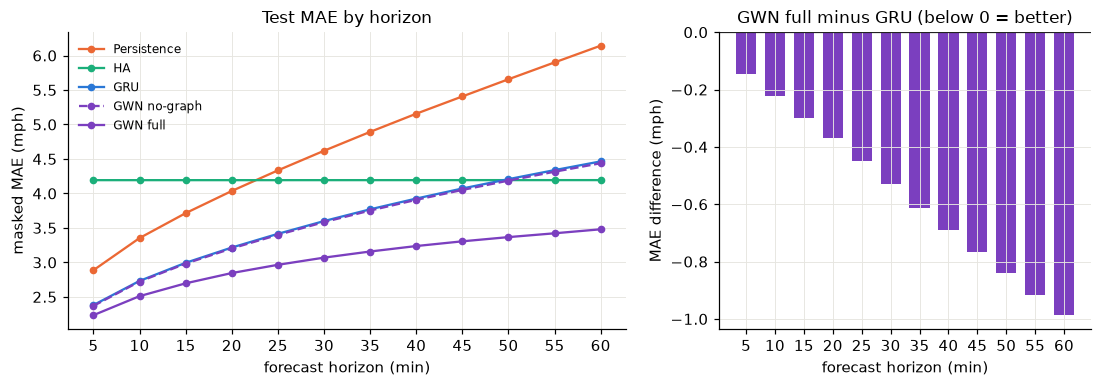

GWN full is below HA up to 60 min
GRU is below HA up to 45 min


In [5]:
steps = np.arange(1, 13)
def hsel(h):
    s = np.zeros_like(obs)
    s[:, h] = True
    return s

per_h = pd.DataFrame({k: [mae(k, hsel(h)) for h in range(12)] for k in MODELS}, index=steps * 5)
per_h.index.name = "horizon (min)"
per_h["GWN full - GRU"] = per_h["GWN full"] - per_h["GRU"]
per_h["% change"] = 100 * (per_h["GWN full"] / per_h["GRU"] - 1)
display(per_h.round(3).T)
per_h.round(3).to_csv(fig_dir / "mae_by_horizon.csv")
numbers["mae_by_horizon"] = per_h.round(3).to_dict()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
for k in MODELS:
    ax[0].plot(per_h.index, per_h[k], LS[k], marker="o", ms=4, color=COL[k], label=k)
ax[0].set(xlabel="forecast horizon (min)", ylabel="masked MAE (mph)", title="Test MAE by horizon", xticks=range(5, 65, 5))
ax[0].legend(fontsize=8)
ax[1].bar(per_h.index, per_h["GWN full - GRU"], width=3.5, color=C4)
ax[1].axhline(0, color="#222222", lw=0.8)
ax[1].set(xlabel="forecast horizon (min)", ylabel="MAE difference (mph)", title="GWN full minus GRU (below 0 = better)",
          xticks=range(5, 65, 5))
save(fig, "R1_mae_by_horizon")
ha_cross = per_h.index[per_h["GWN full"] < per_h["HA"]]
print(f"GWN full is below HA up to {ha_cross.max()} min" if len(ha_cross) else "GWN full never beats HA")
print(f"GRU is below HA up to {per_h.index[per_h['GRU'] < per_h['HA']].max()} min")
numbers["below_ha_until_min"] = {"GWN full": int(ha_cross.max()) if len(ha_cross) else 0,
                                 "GRU": int(per_h.index[per_h["GRU"] < per_h["HA"]].max())}

**Takeaway.** The gap to the GRU grows steadily with the horizon, from 0.15 mph at 5 min to 0.99 mph at 60 min. That is what we would expect if the gain comes from other sensors: at 5 min a sensor's own last reading says nearly everything, while at 60 min the traffic that will arrive is still somewhere else on the network. GWN full stays below the historical average at all 12 horizons; the GRU crossed above it after 45 min.

### Share of sensors where Graph WaveNet beats the GRU

In [6]:
def sensor_mae(k, h):
    o = obs[:, h - 1]
    return np.where(o, err[k][:, h - 1], 0).sum(0) / o.sum(0)

rows = []
for h in (3, 6, 12):
    g, w, n = sensor_mae("GRU", h), sensor_mae("GWN full", h), sensor_mae("GWN no-graph", h)
    rows.append({"horizon": f"{h * 5} min",
                 "GWN full beats GRU": (w < g).mean(),
                 "GWN no-graph beats GRU": (n < g).mean(),
                 "GWN full beats GWN no-graph": (w < n).mean(),
                 "median change (mph)": np.median(w - g),
                 "largest gain (mph)": (w - g).min(),
                 "largest loss (mph)": (w - g).max()})
share = pd.DataFrame(rows).set_index("horizon")
display(share.round(3))
share.round(3).to_csv(fig_dir / "share_sensors_better.csv")
numbers["share_sensors"] = share.round(3).reset_index().to_dict("records")

,GWN full beats GRU,GWN no-graph beats GRU,GWN full beats GWN no-graph,median change (mph),largest gain (mph),largest loss (mph)
horizon,,,,,,
15 min,0.995,0.744,0.995,-0.258,-1.206,0.027
30 min,0.995,0.686,0.995,-0.486,-1.992,0.003
60 min,1.000,0.749,1.000,-0.928,-3.736,-0.053


**Takeaway.** The improvement is not driven by a few sensors: GWN full has lower MAE than the GRU at 99.5% of sensors at 15 and 30 min and at all 207 at 60 min (median gain 0.93 mph, largest 3.74 mph). The one sensor that gets worse at 15 min loses 0.03 mph. GWN no-graph beats the GRU at only 69-75% of sensors and by tiny margins.

## 3. Congested (target < 40 mph) vs free-flow (>= 40 mph)
This was the main CI2 failure: in congestion the GRU lost to plain persistence at every horizon.

,horizon,regime,share of targets,Persistence,HA,GRU,GWN no-graph,GWN full
0,15 min,congested (<40),0.124,7.341,12.899,7.448,7.350,6.364
1,15 min,free-flow (>=40),0.876,3.203,2.964,2.366,2.366,2.179
2,30 min,congested (<40),0.124,9.674,12.900,10.182,10.085,7.975
3,30 min,free-flow (>=40),0.876,3.905,2.964,2.670,2.666,2.377
4,60 min,congested (<40),0.124,13.418,12.905,14.456,14.461,9.704
5,60 min,free-flow (>=40),0.876,5.117,2.965,3.056,3.024,2.602


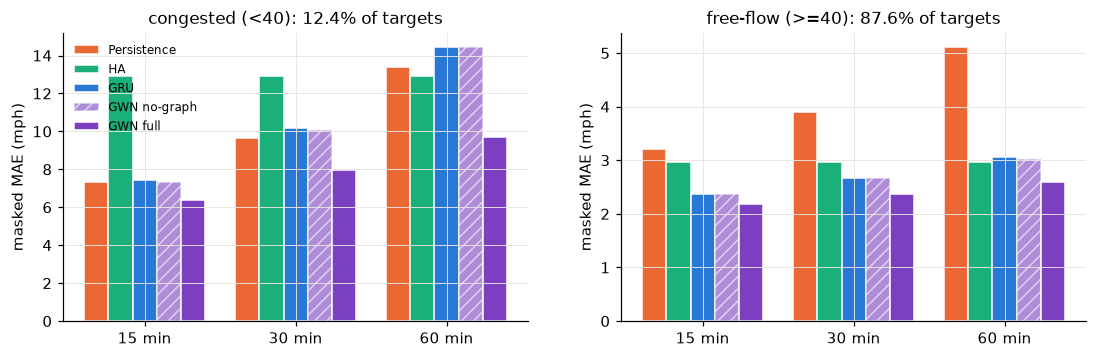

congested, 15 min: GRU 7.45, GWN no-graph 7.35, GWN full 6.36, persistence 7.34, HA 12.90
congested, 30 min: GRU 10.18, GWN no-graph 10.09, GWN full 7.97, persistence 9.67, HA 12.90
congested, 60 min: GRU 14.46, GWN no-graph 14.46, GWN full 9.70, persistence 13.42, HA 12.90


In [7]:
congested, free_flow = obs & (y < 40), obs & (y >= 40)
rows = []
for h in (3, 6, 12):
    for regime, R in [("congested (<40)", congested), ("free-flow (>=40)", free_flow)]:
        sel = np.zeros_like(obs)
        sel[:, h - 1] = True
        sel &= R
        rows.append({"horizon": f"{h * 5} min", "regime": regime, "share of targets": sel.sum() / obs[:, h - 1].sum(),
                     **{k: mae(k, sel) for k in MODELS}})
reg = pd.DataFrame(rows)
display(reg.round(3))
reg.round(3).to_csv(fig_dir / "mae_congested_vs_free.csv", index=False)
numbers["regime"] = reg.round(2).to_dict("records")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, regime in zip(axs, reg.regime.unique()):
    d = reg[reg.regime == regime].set_index("horizon")
    bars(ax, d, MODELS)
    ax.set(ylabel="masked MAE (mph)", title=f"{regime}: {d['share of targets'].iloc[0]:.1%} of targets")
axs[0].legend(fontsize=8)
save(fig, "R2_congested_vs_free")
cong = reg[reg.regime == "congested (<40)"].set_index("horizon")
for h in cong.index:
    print(f"congested, {h}: GRU {cong.loc[h, 'GRU']:.2f}, GWN no-graph {cong.loc[h, 'GWN no-graph']:.2f}, "
          f"GWN full {cong.loc[h, 'GWN full']:.2f}, persistence {cong.loc[h, 'Persistence']:.2f}, HA {cong.loc[h, 'HA']:.2f}")

**Takeaway.** This is where the CI2 failure is repaired. In congestion the GRU lost to persistence at every horizon; GWN full now beats persistence at all three (6.36 vs 7.34, 7.97 vs 9.67, 9.70 vs 13.42 mph) and cuts the GRU's 60-min congested MAE from 14.46 to 9.70. GWN no-graph is no better than the GRU there (14.46). Congested targets are 12.4% of the test set and their error is still 3.7 times the free-flow error (9.70 vs 2.60 mph at 60 min), so congestion remains the hard regime.

## 4. Ablation: how much of the gain comes from the graph?
`gwnet_nograph` is the same network as `gwnet_full` with every graph convolution replaced by a 1x1 convolution, so no information moves between sensors. Everything else (features, layers, channels, dropout, optimizer, seed, epoch budget) is identical. That lets us split the total gain over the GRU into two parts:
* **architecture** = GRU minus GWN no-graph (temporal convolutions, more capacity, batch norm), and
* **graph** = GWN no-graph minus GWN full (the only difference is the graph convolutions).

,GRU,GWN no-graph,GWN full,total gain,from architecture,from graph,graph share of gain
slice,,,,,,,
all horizons,3.593,3.576,3.024,0.568,0.017,0.551,0.970
15 min,2.994,2.982,2.697,0.298,0.012,0.286,0.959
30 min,3.599,3.584,3.069,0.530,0.015,0.515,0.971
60 min,4.465,4.438,3.480,0.985,0.027,0.958,0.973
"15 min, congested",7.448,7.350,6.364,1.084,0.098,0.986,0.910
"30 min, congested",10.182,10.085,7.975,2.208,0.097,2.111,0.956
"60 min, congested",14.456,14.461,9.704,4.752,-0.005,4.757,1.001
"15 min, free-flow",2.366,2.366,2.179,0.187,0.000,0.187,1.000
"30 min, free-flow",2.670,2.666,2.377,0.293,0.004,0.290,0.987


correlation of test errors with the GRU's errors: {'GWN no-graph': 0.989, 'GWN full': 0.73}
prediction range (mph): {'GRU': [2.3, 74.8], 'GWN no-graph': [1.6, 72.9], 'GWN full': [-3.9, 73.0]}


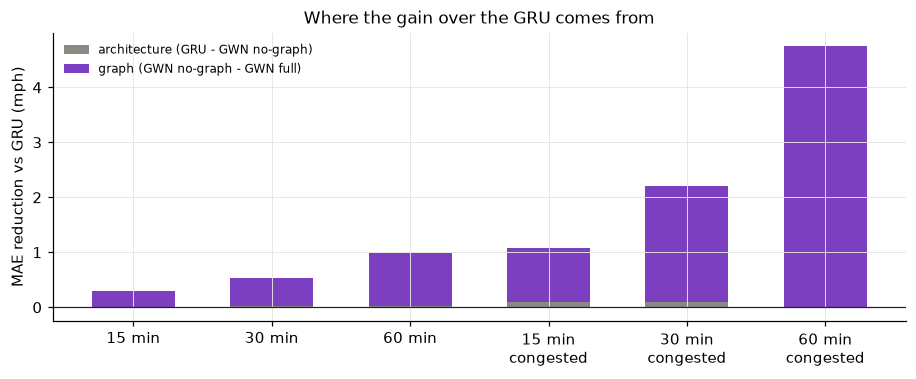

In [8]:
def split_gain(label, sel):
    g, n, w = mae("GRU", sel), mae("GWN no-graph", sel), mae("GWN full", sel)
    total = g - w
    return {"slice": label, "GRU": g, "GWN no-graph": n, "GWN full": w, "total gain": total,
            "from architecture": g - n, "from graph": n - w,
            "graph share of gain": (n - w) / total if total > 0 else np.nan}

rows = [split_gain("all horizons", np.ones_like(obs))]
for h in (3, 6, 12):
    rows.append(split_gain(f"{h * 5} min", hsel(h - 1)))
for h in (3, 6, 12):
    rows.append(split_gain(f"{h * 5} min, congested", hsel(h - 1) & congested))
for h in (3, 6, 12):
    rows.append(split_gain(f"{h * 5} min, free-flow", hsel(h - 1) & free_flow))
abl = pd.DataFrame(rows).set_index("slice")
display(abl.round(3))
abl.round(3).to_csv(fig_dir / "ablation_graph_vs_architecture.csv")
numbers["ablation"] = abl.round(3).reset_index().to_dict("records")
# two per-sensor models: how similar are their errors? (and the prediction range, as a sanity check)
signed = {k: (preds[k] - y)[obs] for k in NEURAL}
numbers["error_corr_with_GRU"] = {k: round(float(np.corrcoef(signed["GRU"], signed[k])[0, 1]), 3) for k in NEURAL if k != "GRU"}
numbers["pred_min_max_mph"] = {k: [round(float(preds[k].min()), 1), round(float(preds[k].max()), 1)] for k in NEURAL}
print("correlation of test errors with the GRU's errors:", numbers["error_corr_with_GRU"])
print("prediction range (mph):", numbers["pred_min_max_mph"])

fig, ax = plt.subplots(figsize=(10, 3.4))
d = abl.loc[["15 min", "30 min", "60 min", "15 min, congested", "30 min, congested", "60 min, congested"]]
xs = np.arange(len(d))
ax.bar(xs, d["from architecture"], 0.6, color=GRAY, label="architecture (GRU - GWN no-graph)")
ax.bar(xs, d["from graph"], 0.6, bottom=d["from architecture"].clip(lower=0), color=C4, label="graph (GWN no-graph - GWN full)")
ax.axhline(0, color="#222222", lw=0.8)
ax.set_xticks(xs)
ax.set_xticklabels([s.replace(", ", "\n") for s in d.index])
ax.set(ylabel="MAE reduction vs GRU (mph)", title="Where the gain over the GRU comes from")
ax.legend(fontsize=8)
save(fig, "R3_ablation")

**Takeaway.** We split the gain as (GRU - no-graph) = architecture and (no-graph - full) = graph. Over all horizons the total gain is 0.568 mph, of which 0.017 comes from the architecture and 0.551 (97%) from the graph. The split is the same in every slice (91-100% graph), and in 60-min congestion the architecture contributes nothing (-0.005) while the graph contributes 4.76 mph. In other words, a model that only sees one sensor's history seems to hit the same ceiling whether it is a GRU or a dilated CNN; what moves the number is letting sensors see each other. This is one seed per model. The four GRU seeds in CI2 differed by 0.002-0.008 mph, so the 0.017 mph architecture effect is at the edge of seed noise, while the graph effect is about 70 times larger.

## 5. The CI2 failure analyses again, GRU vs Graph WaveNet
Each analysis below uses the same definitions as the CI2 notebook.
### 5.1 MAE by time of day, weekday vs weekend

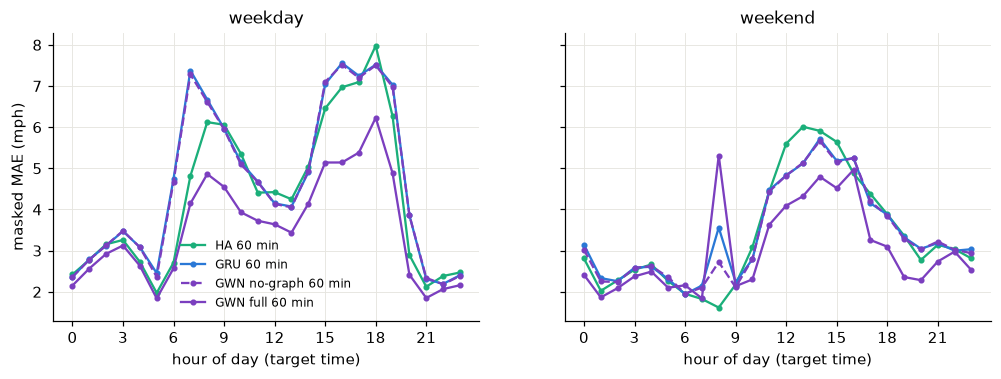

GRU {'wd_peak_hour': 16, 'wd_peak_mae': np.float64(7.56), 'wd_night_0_4': np.float64(2.97), 'wd_am_7_9': np.float64(6.67), 'wd_pm_15_18': np.float64(7.34), 'wd_mean': np.float64(4.67), 'we_mean': np.float64(3.42), 'weekday_hours_worse_than_HA': [1, 3, 4, 5, 6, 7, 8, 11, 15, 16, 17, 19, 20, 21]}
GWN no-graph {'wd_peak_hour': 16, 'wd_peak_mae': np.float64(7.52), 'wd_night_0_4': np.float64(2.97), 'wd_am_7_9': np.float64(6.61), 'wd_pm_15_18': np.float64(7.33), 'wd_mean': np.float64(4.65), 'we_mean': np.float64(3.37), 'weekday_hours_worse_than_HA': [1, 3, 4, 5, 6, 7, 8, 11, 15, 16, 17, 19, 20, 21]}
GWN full {'wd_peak_hour': 18, 'wd_peak_mae': np.float64(6.23), 'wd_night_0_4': np.float64(2.68), 'wd_am_7_9': np.float64(4.52), 'wd_pm_15_18': np.float64(5.47), 'wd_mean': np.float64(3.56), 'we_mean': np.float64(3.03), 'weekday_hours_worse_than_HA': []}
weekday GRU - GWN full at 60 min, by hour: {0: 0.21, 1: 0.22, 2: 0.2, 3: 0.35, 4: 0.45, 5: 0.61, 6: 2.18, 7: 3.23, 8: 1.81, 9: 1.42, 10: 1.21, 11

In [9]:
hour = ts.hour.to_numpy()[target_idx]
wkend = (ts.dayofweek.to_numpy() >= 5)[target_idx]
rows = []
for h in (3, 12):
    o = obs[:, h - 1]
    for k in MODELS:
        e = np.where(o, err[k][:, h - 1], 0).sum(1)
        c = o.sum(1)
        g = pd.DataFrame({"hour": hour[:, h - 1], "weekend": wkend[:, h - 1], "e": e, "c": c}).groupby(["weekend", "hour"]).sum()
        for (we, hr), r in g.iterrows():
            rows.append({"horizon": h * 5, "model": k, "weekend": we, "hour": hr, "MAE": r.e / r.c})
tod = pd.DataFrame(rows)
tod.to_csv(fig_dir / "mae_by_tod.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, we in zip(axs, (False, True)):
    for k in ["HA", "GRU", "GWN no-graph", "GWN full"]:
        d = tod[(tod.horizon == 60) & (tod.model == k) & (tod.weekend == we)]
        ax.plot(d.hour, d.MAE, LS[k], marker="o", ms=3, color=COL[k], label=f"{k} 60 min")
    ax.set(xlabel="hour of day (target time)", title="weekend" if we else "weekday", xticks=range(0, 24, 3))
axs[0].set_ylabel("masked MAE (mph)")
axs[0].legend(fontsize=8)
save(fig, "FA1_mae_by_tod")

wd = tod[(tod.horizon == 60) & (~tod.weekend)].pivot(index="hour", columns="model", values="MAE")
we_ = tod[(tod.horizon == 60) & (tod.weekend)].pivot(index="hour", columns="model", values="MAE")
tod_num = {}
for k in NEURAL:
    tod_num[k] = {
        "wd_peak_hour": int(wd[k].idxmax()),
        "wd_peak_mae": round(wd[k].max(), 2),
        "wd_night_0_4": round(wd[k].loc[0:4].mean(), 2),
        "wd_am_7_9": round(wd[k].loc[7:9].mean(), 2),
        "wd_pm_15_18": round(wd[k].loc[15:18].mean(), 2),
        "wd_mean": round(wd[k].mean(), 2),
        "we_mean": round(we_[k].mean(), 2),
        "weekday_hours_worse_than_HA": wd.index[wd[k] > wd["HA"]].tolist(),
    }
    print(k, tod_num[k])
numbers["tod"] = tod_num
gain_by_hour = (wd["GRU"] - wd["GWN full"]).round(2)
print("weekday GRU - GWN full at 60 min, by hour:", gain_by_hour.to_dict())
numbers["tod"]["weekday_gain_by_hour"] = gain_by_hour.to_dict()

**Takeaway.** The GRU's weekday error peaked in the rush hours (6.67 mph at 7-9 h, 7.34 at 15-18 h) and it was worse than the historical average in 14 of 24 weekday hours. GWN full brings those to 4.52 and 5.47 mph and is not worse than the historical average in any weekday hour. The gain is largest exactly at congestion onset (3.23 mph at 7 h, 2.41 at 16 h) and smallest at night (about 0.2 mph), when there is nothing to propagate. The rush hours are still its worst hours, and the evening peak improved less than the morning one.

### 5.2 Lag around sharp drops
Same events as CI2: the observed speed falls by more than 15 mph within 30 min, ending at *t0*, at most one event per sensor per hour. The lag is the number of 5-min steps between the truth and the prediction first falling below the midpoint of the drop.

9,974 sharp-drop events at 207 sensors (CI2 found 9,974)


,model,horizon (min),events,never crosses,median lag (steps),mean lag (steps),IQR,lag < horizon,crosses with lag < horizon (all events),"MAE in [t0, t0+60]"
0,Persistence,15,9974,0.02,3.0,2.07,3-3,0.13,0.12,10.00
1,Persistence,60,9974,0.02,12.0,6.99,0-12,0.36,0.35,16.77
2,GRU,15,9974,0.25,3.0,4.24,3-4,0.09,0.07,9.57
3,GRU,60,9974,0.40,12.0,9.83,9-13,0.33,0.20,15.99
4,GWN no-graph,15,9974,0.22,3.0,4.00,3-4,0.11,0.09,9.51
5,GWN no-graph,60,9974,0.41,12.0,9.59,7-13,0.37,0.22,15.97
6,GWN full,15,9974,0.36,3.0,3.43,1-4,0.41,0.27,7.87
7,GWN full,60,9974,0.48,4.0,4.50,-1-11,0.77,0.40,11.14


median 5-min steps (of 13) the truth stays below the midpoint after t0, 60-min forecasts: {'GWN full crosses': 9.0, 'GWN full never crosses': 3.0, 'GRU crosses': 9.0, 'GRU never crosses': 2.0}


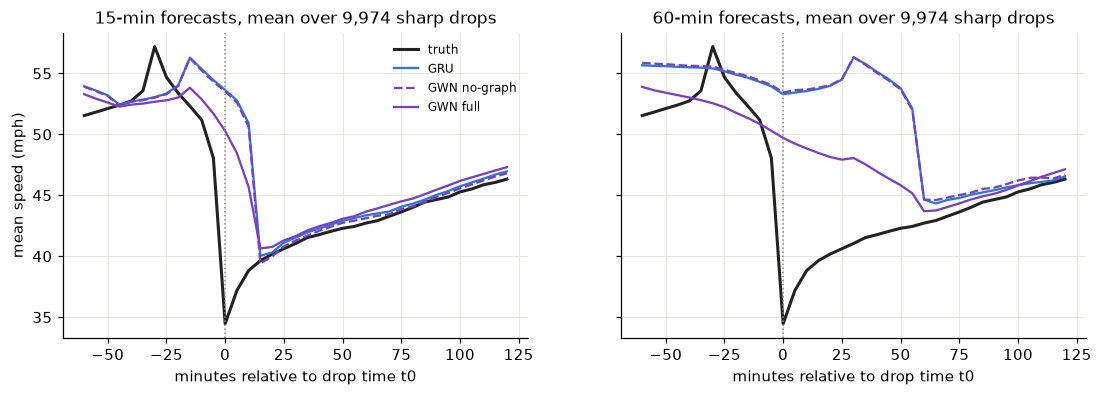

In [10]:
n_times = len(ts)
def series(k, h):
    # predictions of model k at horizon h, placed at the time they predict: (time, sensor)
    out = np.full((n_times, y.shape[2]), np.nan, np.float32)
    out[target_idx[:, h - 1]] = preds[k][:, h - 1]
    return out

pred_series = {(k, h): series(k, h) for k in MODELS for h in (3, 12)}
truth = np.where(raw > 0, raw, np.nan).astype(np.float32)
drop = np.full_like(truth, np.nan)
drop[6:] = truth[:-6] - truth[6:]  # speed drop over the last 30 min

offsets = np.arange(-12, 25)
cand = (drop > 15) & np.isfinite(drop)
lo, hi = s_te + 23 + 12, e_te - 25            # every offset has a 60-min-ahead prediction
ev = []
for n in range(y.shape[2]):
    last = -10**9
    for t in np.where(cand[lo:hi, n])[0] + lo:
        if t - last >= 12:
            ev.append((t, n))
            last = t
ev = np.array(ev)
print(f"{len(ev):,} sharp-drop events at {len(np.unique(ev[:, 1]))} sensors (CI2 found 9,974)")
tt = ev[:, :1] + offsets[None]
aligned = {"truth": truth[tt, ev[:, 1:2]]}
for k in MODELS:
    for h in (3, 12):
        aligned[(k, h)] = pred_series[(k, h)][tt, ev[:, 1:2]]
pre = np.nanmean(aligned["truth"][:, (offsets >= -12) & (offsets <= -7)], 1)
post = np.nanmin(aligned["truth"][:, (offsets >= 0) & (offsets <= 12)], 1)
mid = (pre + post) / 2
search = offsets >= -6
def first_cross(a):
    below = (a < mid[:, None]) & search[None]
    return np.where(below.any(1), offsets[np.argmax(below, 1)], np.nan)

c_true = first_cross(aligned["truth"])
after_t0 = (offsets >= 0) & (offsets <= 12)
lag_rows = []
lags = {}
for k in ["Persistence", "GRU", "GWN no-graph", "GWN full"]:
    for h in (3, 12):
        lag = first_cross(aligned[(k, h)]) - c_true
        lags[(k, h)] = lag
        ok = np.isfinite(lag)
        lag_rows.append({
            "model": k,
            "horizon (min)": h * 5,
            "events": len(lag),
            "never crosses": 1 - ok.mean(),
            "median lag (steps)": np.median(lag[ok]),
            "mean lag (steps)": lag[ok].mean(),
            "IQR": f"{np.percentile(lag[ok], 25):.0f}-{np.percentile(lag[ok], 75):.0f}",
            "lag < horizon": (lag[ok] < h).mean(),
            # the lag columns only cover events that cross, so also give the share of ALL events
            "crosses with lag < horizon (all events)": (lag[ok] < h).sum() / len(lag),
            "MAE in [t0, t0+60]": float(np.nanmean(np.abs(aligned[(k, h)] - aligned["truth"])[:, after_t0])),
        })
lagtab = pd.DataFrame(lag_rows)
display(lagtab.round(2))
lagtab.round(2).to_csv(fig_dir / "drop_lag.csv", index=False)
# how long does the truth stay below the midpoint in the hour after t0, when GWN full follows it and when it doesn't?
steps_below = (aligned["truth"] < mid[:, None])[:, after_t0].sum(1)
follows = np.isfinite(lags[("GWN full", 12)])
dur = {"GWN full crosses": float(np.median(steps_below[follows])), "GWN full never crosses": float(np.median(steps_below[~follows])),
       "GRU crosses": float(np.median(steps_below[np.isfinite(lags[("GRU", 12)])])), "GRU never crosses": float(np.median(steps_below[~np.isfinite(lags[("GRU", 12)])]))}
print("median 5-min steps (of 13) the truth stays below the midpoint after t0, 60-min forecasts:", dur)
numbers["drop_duration_steps"] = dur
numbers["drop_lag"] = {"events": int(len(ev)), "sensors": int(len(np.unique(ev[:, 1]))), "table": lagtab.round(2).to_dict("records")}

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
xm = offsets * 5
for ax, h in zip(axs, (3, 12)):
    ax.plot(xm, np.nanmean(aligned["truth"], 0), color=COL["truth"], lw=2, label="truth")
    for k in NEURAL:
        ax.plot(xm, np.nanmean(aligned[(k, h)], 0), LS[k], color=COL[k], label=k)
    ax.axvline(0, color=GRAY, ls=":", lw=1)
    ax.set(xlabel="minutes relative to drop time t0", title=f"{h * 5}-min forecasts, mean over {len(ev):,} sharp drops")
axs[0].set_ylabel("mean speed (mph)")
axs[0].legend(fontsize=8)
save(fig, "FA2_drop_lag")

**Takeaway.** At 60 min the GRU's median lag behind a sharp drop was 12 steps, i.e. it only reacted once the drop was in its own input. For GWN full the median is 4 steps, and it crosses the midpoint with a lag shorter than the horizon in 40% of all events (GRU 20%); the error in the hour after the drop falls from 15.99 to 11.14 mph. **What got worse:** GWN full never follows the drop at all in 48% of events at 60 min (GRU 40%) and 36% at 15 min (GRU 25%). The lag columns only cover the events a model does follow, so they flatter it. The drops it ignores are mostly brief (the truth stays below the midpoint for a median of 3 of 13 steps, against 9 for the ones it follows), which fits a model that averages over neighbours and so smooths away short dips at a single sensor.

### 5.3 MAE vs missing values in the input window

,missing input steps,horizon (min),share of targets,Persistence,HA,GRU,GWN no-graph,GWN full
0,0,15,0.943,3.455,4.154,2.944,2.932,2.651
1,0,60,0.926,5.313,4.153,4.376,4.353,3.384
2,1-3,15,0.028,3.804,4.679,3.288,3.260,2.957
3,1-3,60,0.031,5.278,4.461,4.418,4.391,3.477
4,4-6,15,0.011,3.929,5.542,3.573,3.556,3.183
5,4-6,60,0.014,6.323,5.416,5.561,5.573,4.427
6,7-11,15,0.013,4.195,4.658,3.793,3.817,3.549
7,7-11,60,0.015,6.210,4.812,5.302,5.420,4.618
8,12 (all),15,0.004,59.135,4.563,8.287,8.261,7.251
9,12 (all),60,0.015,59.537,4.382,8.275,7.818,7.480


,"all 12 own inputs missing, and",targets,Persistence,HA,GRU,GWN no-graph,GWN full
0,network also down (>90% of sensors missing),15665,60.23,4.18,7.88,7.33,7.74
1,only some sensors down (<=90% missing),2751,55.60,5.53,10.54,10.60,5.99


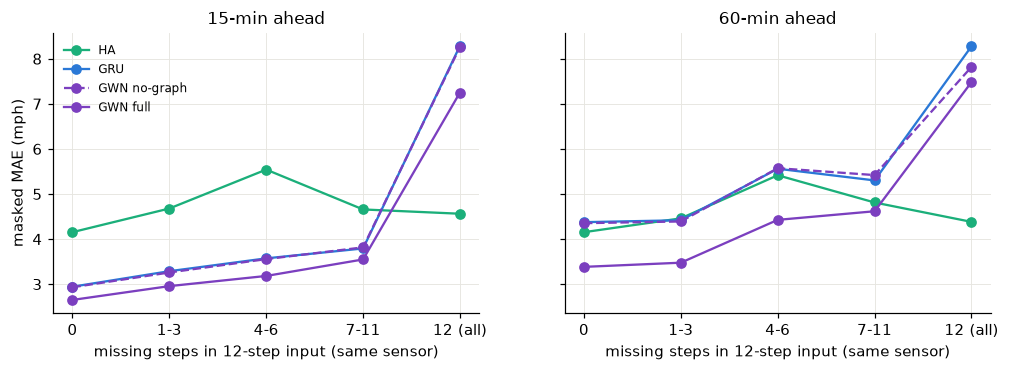

In [11]:
kmiss = np.rint(x_missing * 12).astype(int)                     # (windows, sensors) missing input steps
bins = [(0, 0, "0"), (1, 3, "1-3"), (4, 6, "4-6"), (7, 11, "7-11"), (12, 12, "12 (all)")]
rows = []
for lo_, hi_, lab in bins:
    b = (kmiss >= lo_) & (kmiss <= hi_)
    for h in (3, 12):
        sel = np.zeros_like(obs)
        sel[:, h - 1] = b
        sel &= obs
        rows.append({"missing input steps": lab, "horizon (min)": h * 5, "share of targets": sel.sum() / obs[:, h - 1].sum(),
                     **{k: mae(k, sel) for k in MODELS}})
miss = pd.DataFrame(rows)
display(miss.round(3))
miss.round(3).to_csv(fig_dir / "mae_vs_missing.csv", index=False)
numbers["missing"] = miss.round(2).to_dict("records")

# all 12 steps missing at this sensor: does it matter whether the rest of the network is also down?
net_missing = (kmiss == 12).mean(1)                              # share of sensors with no input, per window
own_all = kmiss == 12
rows = []
for label, wsel in [("network also down (>90% of sensors missing)", net_missing > 0.9),
                    ("only some sensors down (<=90% missing)", net_missing <= 0.9)]:
    sel = np.zeros_like(obs)
    sel[:, 11] = own_all & wsel[:, None]
    sel &= obs
    rows.append({"all 12 own inputs missing, and": label, "targets": int(sel.sum()), **{k: mae(k, sel) for k in MODELS}})
allmiss = pd.DataFrame(rows)
display(allmiss.round(2))
numbers["all_missing_split_60"] = allmiss.round(2).to_dict("records")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, h in zip(axs, (15, 60)):
    d = miss[miss["horizon (min)"] == h].set_index("missing input steps")
    for k in ["HA", "GRU", "GWN no-graph", "GWN full"]:
        ax.plot(d.index, d[k], LS[k], marker="o", color=COL[k], label=k)
    ax.set(xlabel="missing steps in 12-step input (same sensor)", title=f"{h}-min ahead")
axs[0].set_ylabel("masked MAE (mph)")
axs[0].legend(fontsize=8)
save(fig, "FA3_mae_vs_missing")

**Takeaway.** GWN full is better than the GRU in every missing-data bin, but the gain shrinks as inputs go missing (0.99 mph at 60 min with a complete window, 0.80 with all 12 steps missing). The split in the second table explains what the graph can and cannot do: when a sensor's own inputs are all missing but the rest of the network is reporting, the graph fills the gap from the neighbours (5.99 vs 10.60 mph without the graph). When the whole network is down there is nothing to read; GWN full (7.74) is then slightly **worse** than GWN no-graph (7.33), and both lose badly to the historical average (4.18).

### 5.4 Per-sensor MAE, and the CI2 worst-10 sensors before and after

,GRU 60,GWN no-graph 60,GWN full 60,HA,share <40 mph,test missing rate,in-degree,out-degree,change (GWN full - GRU),ci2_rank
sensor_id,,,,,,,,,,
717462,10.08,9.93,7.58,11.75,0.40,0.10,14,13,-2.50,1
718045,9.91,9.85,6.93,7.52,0.30,0.14,6,14,-2.98,2
717461,9.81,9.76,6.85,10.01,0.48,0.20,17,11,-2.96,3
717458,9.68,9.65,6.41,9.04,0.50,0.10,13,15,-3.27,4
773939,9.53,9.58,6.92,9.91,0.25,0.10,3,3,-2.61,5
717466,9.15,9.08,7.30,11.95,0.32,0.10,14,11,-1.85,6
717468,9.14,9.12,7.27,12.76,0.28,0.10,14,14,-1.87,7
716339,9.02,8.74,5.28,7.13,0.56,0.10,15,13,-3.74,8
717472,8.65,8.67,6.48,12.36,0.25,0.13,10,12,-2.17,9


{'mean_GRU': 9.3, 'mean_GWN_nograph': 9.25, 'mean_GWN_full': 6.8, 'improved': 10, 'share_of_abs_err_GRU': 0.101, 'share_of_abs_err_GWN_full': 0.094}
mean change at the CI2 worst 10: -2.51 mph; at the other 197 sensors: -0.91 mph


,GRU 60,GWN full 60,change (GWN full - GRU)
share <40 mph,0.89,0.81,-0.84
test missing rate,0.13,0.16,-0.01
in-degree,0.17,0.14,-0.27
out-degree,0.18,0.09,-0.41


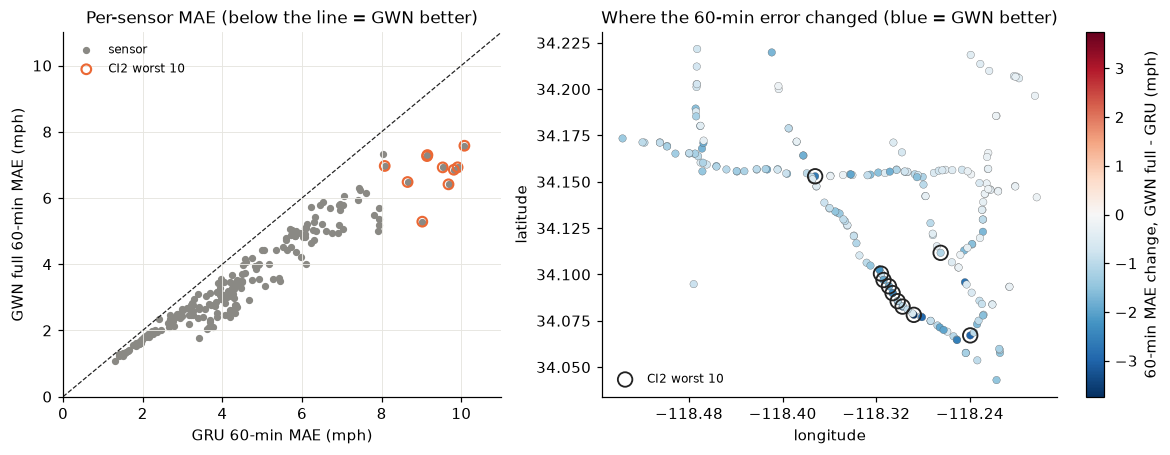

In [12]:
smae = {k: {h: sensor_mae(k, h) for h in (3, 12)} for k in MODELS}
miss_rate = (raw[s_te:e_te] == 0).mean(0)
cong_share = np.nanmean(np.where(np.isfinite(truth[s_te:e_te]), truth[s_te:e_te] < 40, np.nan), 0)
in_deg = (adj > 0.1).sum(0) - 1
out_deg = (adj > 0.1).sum(1) - 1
sens = pd.DataFrame({"sensor_id": sensor_ids, "GRU 60": smae["GRU"][12], "GWN no-graph 60": smae["GWN no-graph"][12],
                     "GWN full 60": smae["GWN full"][12], "HA": smae["HA"][12],
                     "share <40 mph": cong_share, "test missing rate": miss_rate,
                     "in-degree": in_deg, "out-degree": out_deg})
sens["change (GWN full - GRU)"] = sens["GWN full 60"] - sens["GRU 60"]
sens.round(3).to_csv(fig_dir / "per_sensor_mae.csv", index=False)

# our GRU per-sensor numbers must match the CI2 file
ci2_sens = pd.read_csv(CI2 / "figures" / "per_sensor_mae.csv", dtype={"sensor_id": str}).set_index("sensor_id")
assert np.abs(ci2_sens.loc[sensor_ids, "GRU 60"].values - sens["GRU 60"].round(3).values).max() < 2e-3
ci2_worst_ids = ci2_sens.sort_values("GRU 60", ascending=False).head(10).index.tolist()
worst_ci2 = sens.set_index("sensor_id").loc[ci2_worst_ids]
display(worst_ci2.round(2).assign(ci2_rank=range(1, 11)))
worst_ci2.round(3).to_csv(fig_dir / "ci2_worst10_before_after.csv")
tot_err = {k: np.where(obs[:, 11], err[k][:, 11], 0).sum(0) for k in NEURAL}
idx10 = [list(sensor_ids).index(s) for s in ci2_worst_ids]
numbers["ci2_worst10"] = {
    "table": worst_ci2.round(2).reset_index().to_dict("records"),
    "mean_GRU": round(float(worst_ci2["GRU 60"].mean()), 2),
    "mean_GWN_nograph": round(float(worst_ci2["GWN no-graph 60"].mean()), 2),
    "mean_GWN_full": round(float(worst_ci2["GWN full 60"].mean()), 2),
    "improved": int((worst_ci2["change (GWN full - GRU)"] < 0).sum()),
    "share_of_abs_err_GRU": round(float(tot_err["GRU"][idx10].sum() / tot_err["GRU"].sum()), 3),
    "share_of_abs_err_GWN_full": round(float(tot_err["GWN full"][idx10].sum() / tot_err["GWN full"].sum()), 3),
}
print({k: v for k, v in numbers["ci2_worst10"].items() if k != "table"})
others = sens[~sens.sensor_id.isin(ci2_worst_ids)]
print(f"mean change at the CI2 worst 10: {worst_ci2['change (GWN full - GRU)'].mean():+.2f} mph; "
      f"at the other 197 sensors: {others['change (GWN full - GRU)'].mean():+.2f} mph")
numbers["ci2_worst10"]["mean_change_worst10"] = round(float(worst_ci2["change (GWN full - GRU)"].mean()), 2)
numbers["ci2_worst10"]["mean_change_others"] = round(float(others["change (GWN full - GRU)"].mean()), 2)

rho = sens[["GRU 60", "GWN full 60", "change (GWN full - GRU)", "share <40 mph", "test missing rate", "in-degree", "out-degree"]].corr(method="spearman")
display(rho.loc[["share <40 mph", "test missing rate", "in-degree", "out-degree"], ["GRU 60", "GWN full 60", "change (GWN full - GRU)"]].round(2))
numbers["per_sensor"] = {
    "GWN_full": {"min": round(float(sens["GWN full 60"].min()), 2), "median": round(float(sens["GWN full 60"].median()), 2),
                 "p90": round(float(sens["GWN full 60"].quantile(0.9)), 2), "max": round(float(sens["GWN full 60"].max()), 2)},
    "GRU": {"min": round(float(sens["GRU 60"].min()), 2), "median": round(float(sens["GRU 60"].median()), 2),
            "p90": round(float(sens["GRU 60"].quantile(0.9)), 2), "max": round(float(sens["GRU 60"].max()), 2)},
    "spearman": rho.loc[["share <40 mph", "test missing rate", "in-degree", "out-degree"],
                        ["GRU 60", "GWN full 60", "change (GWN full - GRU)"]].round(2).to_dict(),
}

loc = locations.reindex(sensor_ids)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 1.3]})
lim = float(np.ceil(max(sens["GRU 60"].max(), sens["GWN full 60"].max())))
axs[0].scatter(sens["GRU 60"], sens["GWN full 60"], s=14, color=GRAY, label="sensor")
axs[0].scatter(worst_ci2["GRU 60"], worst_ci2["GWN full 60"], s=40, facecolor="none", edgecolor=C2, lw=1.4, label="CI2 worst 10")
axs[0].plot([0, lim], [0, lim], color="#222222", lw=0.8, ls="--")
axs[0].set(xlabel="GRU 60-min MAE (mph)", ylabel="GWN full 60-min MAE (mph)", xlim=(0, lim), ylim=(0, lim),
           title="Per-sensor MAE (below the line = GWN better)")
axs[0].legend(fontsize=8)
vmax = float(np.abs(sens["change (GWN full - GRU)"]).max())
sc = axs[1].scatter(loc.longitude, loc.latitude, c=sens["change (GWN full - GRU)"], cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                    s=24, edgecolor="#555555", linewidth=0.2)
w = loc.loc[ci2_worst_ids]
axs[1].scatter(w.longitude, w.latitude, s=90, facecolor="none", edgecolor="#222222", lw=1.2, label="CI2 worst 10")
plt.colorbar(sc, ax=axs[1], label="60-min MAE change, GWN full - GRU (mph)")
axs[1].xaxis.set_major_locator(plt.MaxNLocator(5))
axs[1].set(xlabel="longitude", ylabel="latitude", title="Where the 60-min error changed (blue = GWN better)")
axs[1].legend(loc="lower left", fontsize=8)
axs[1].grid(False)
save(fig, "FA4_sensor_mae")

**Takeaway.** All ten of the GRU's worst sensors improve, by 2.51 mph on average against 0.91 mph at the other 197 sensors, and their mean 60-min MAE falls from 9.30 to 6.80. Two cautions. First, these sensors were picked for having the largest GRU error, so part of that extra gain is selection (regression to the mean). Second, the ranking barely changes: per-sensor error still tracks how often the sensor is congested (Spearman 0.81 for GWN full, 0.89 for the GRU), and these ten still carry 9.4% of the total absolute error (10.1% before).

### 5.5 The CI2 neighbour-lead events: a direct test of the CI2 hypothesis
CI2 found 892 moments at its worst 10 sensors where the GRU's 60-min forecast was more than 15 mph too high, and showed that downstream neighbours had often slowed down first. If the graph carries that early warning, Graph WaveNet's error on **these exact events** should be lower.

One caution: the events were picked because the GRU was badly wrong, so any other model looks better on them just by regression to the mean. The fair comparison is therefore **GWN full vs GWN no-graph**. Neither was used to pick the events, and they differ only in the graph.

,n,GRU 60,GWN no-graph 60,GWN full 60,graph effect (full - no-graph),full beats no-graph,full beats GRU,GRU bias at t0,GWN no-graph bias at t0,GWN full bias at t0
events,,,,,,,,,,
all 892 events,892,24.79,24.78,16.47,-8.31,0.78,0.76,25.55,25.54,17.40
a neighbour dropped earlier,796,25.09,25.02,16.31,-8.71,0.79,0.77,25.68,25.63,16.94
no neighbour dropped earlier,96,22.37,22.78,17.81,-4.97,0.72,0.71,24.43,24.83,21.20
an out-of-i neighbour dropped earlier,727,25.75,25.68,16.35,-9.33,0.81,0.78,25.75,25.65,16.46
no out-of-i neighbour dropped earlier,165,20.58,20.83,17.01,-3.82,0.67,0.68,24.66,25.04,21.52


graph effect on the CI2 events: -8.31 mph (95% bootstrap CI -9.17 to -7.50)


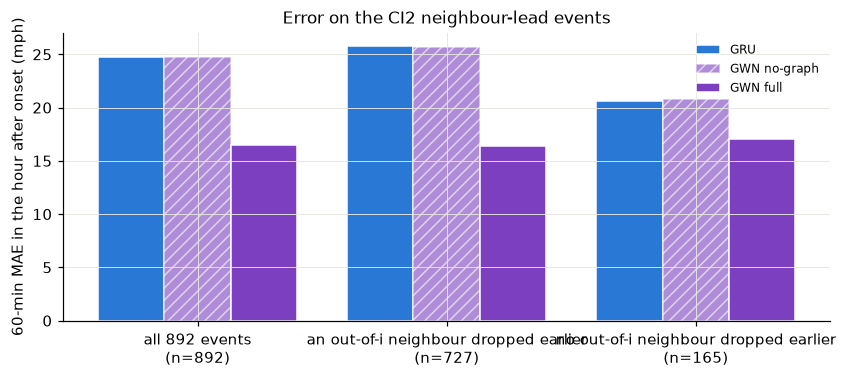

In [13]:
events = pd.read_csv(CI2 / "figures" / "worst_sensor_neighbor_events.csv", dtype={"sensor_id": str}, parse_dates=["t0", "tau"])
sid_to_idx = {s: i for i, s in enumerate(sensor_ids)}
ev_n = events.sensor_id.map(sid_to_idx).to_numpy()
ev_t = ts.get_indexer(events.t0)
assert (ev_t >= 0).all() and len(events) == 892
hour_after = ev_t[:, None] + np.arange(12)[None]               # the hour starting at the event
for k in NEURAL:
    for h in (3, 12):
        e = np.abs(pred_series[(k, h)][hour_after, ev_n[:, None]] - truth[hour_after, ev_n[:, None]])
        events[f"{k} {h * 5}"] = np.nanmean(e, 1).astype(float)
    events[f"{k} bias at t0"] = (pred_series[(k, 12)][ev_t, ev_n] - truth[ev_t, ev_n]).astype(float)

rows = []
groups = [("all 892 events", np.ones(len(events), bool)),
          ("a neighbour dropped earlier", (events["any nbr earlier"] == True).to_numpy()),
          ("no neighbour dropped earlier", ~(events["any nbr earlier"] == True).to_numpy()),
          ("an out-of-i neighbour dropped earlier", (events["out: share earlier"] > 0).to_numpy()),
          ("no out-of-i neighbour dropped earlier", ~(events["out: share earlier"] > 0).to_numpy())]
for label, g in groups:
    d = events[g]
    rows.append({
        "events": label, "n": len(d),
        "GRU 60": d["GRU 60"].mean(), "GWN no-graph 60": d["GWN no-graph 60"].mean(), "GWN full 60": d["GWN full 60"].mean(),
        "graph effect (full - no-graph)": (d["GWN full 60"] - d["GWN no-graph 60"]).mean(),
        "full beats no-graph": (d["GWN full 60"] < d["GWN no-graph 60"]).mean(),
        "full beats GRU": (d["GWN full 60"] < d["GRU 60"]).mean(),
        "GRU bias at t0": d["GRU bias at t0"].mean(), "GWN no-graph bias at t0": d["GWN no-graph bias at t0"].mean(),
        "GWN full bias at t0": d["GWN full bias at t0"].mean(),
    })
nbr = pd.DataFrame(rows).set_index("events")
display(nbr.round(2))
nbr.round(3).to_csv(fig_dir / "neighbor_events_gru_vs_gwn.csv")
numbers["neighbor_events"] = nbr.round(3).reset_index().to_dict("records")

# paired bootstrap over events for the graph effect (full - no-graph), 60-min MAE in the hour after onset
rng = np.random.default_rng(6600)
diff = (events["GWN full 60"] - events["GWN no-graph 60"]).dropna().to_numpy()
boot = np.array([rng.choice(diff, len(diff)).mean() for _ in range(2000)])
ci = np.percentile(boot, [2.5, 97.5])
print(f"graph effect on the CI2 events: {diff.mean():+.2f} mph (95% bootstrap CI {ci[0]:+.2f} to {ci[1]:+.2f})")
numbers["neighbor_events_graph_effect"] = {"mean": round(float(diff.mean()), 3), "ci_low": round(float(ci[0]), 3), "ci_high": round(float(ci[1]), 3)}

fig, ax = plt.subplots(figsize=(9, 3.4))
d = nbr.loc[["all 892 events", "an out-of-i neighbour dropped earlier", "no out-of-i neighbour dropped earlier"]].copy()
d = d.rename(columns={"GRU 60": "GRU", "GWN no-graph 60": "GWN no-graph", "GWN full 60": "GWN full"})
d.index = [f"{i}\n(n={int(n)})" for i, n in zip(d.index, d.n)]
bars(ax, d, NEURAL)
ax.set(ylabel="60-min MAE in the hour after onset (mph)", title="Error on the CI2 neighbour-lead events")
ax.legend(fontsize=8)
save(fig, "FA5_neighbor_events")

**Takeaway.** On the 892 CI2 events the GRU's 60-min error was 24.79 mph and GWN full's is 16.47. Because the events were selected for large GRU error, the fair comparison is full vs no-graph: the graph removes 8.31 mph (95% bootstrap CI 7.50 to 9.17) and helps in 78% of the events. The effect is larger when a neighbour had already dropped (-8.71 mph, n = 796) than when none had (-4.97 mph, n = 96), which supports the CI2 hypothesis that neighbours carry an early warning. It is not the whole story, though: the graph still helps when no direct neighbour had dropped, and 16.47 mph is still a very large error.

## 6. The three CI2 example days, now with Graph WaveNet
Same sensors and days as CI2 (read from CI2's `qualitative_cases.csv`). Each prediction is drawn at the time it predicts.

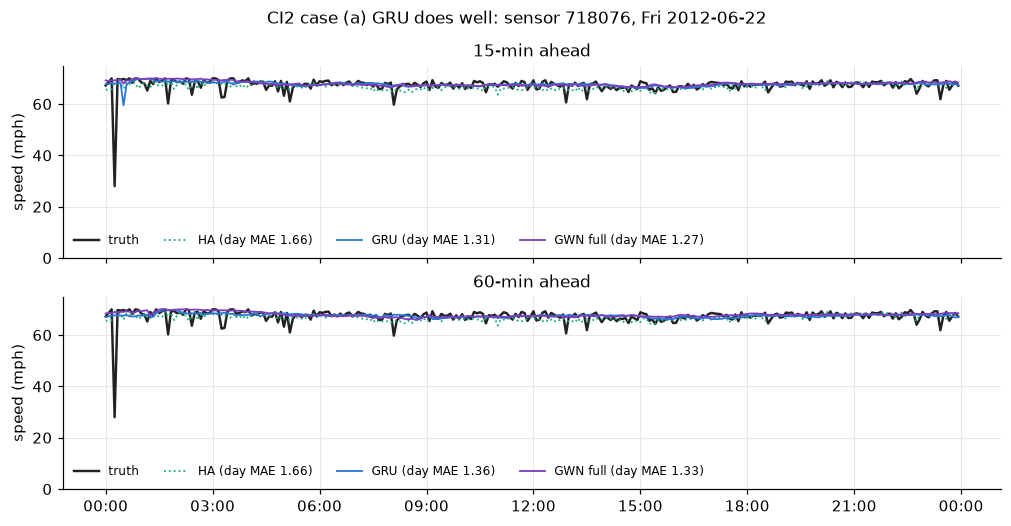

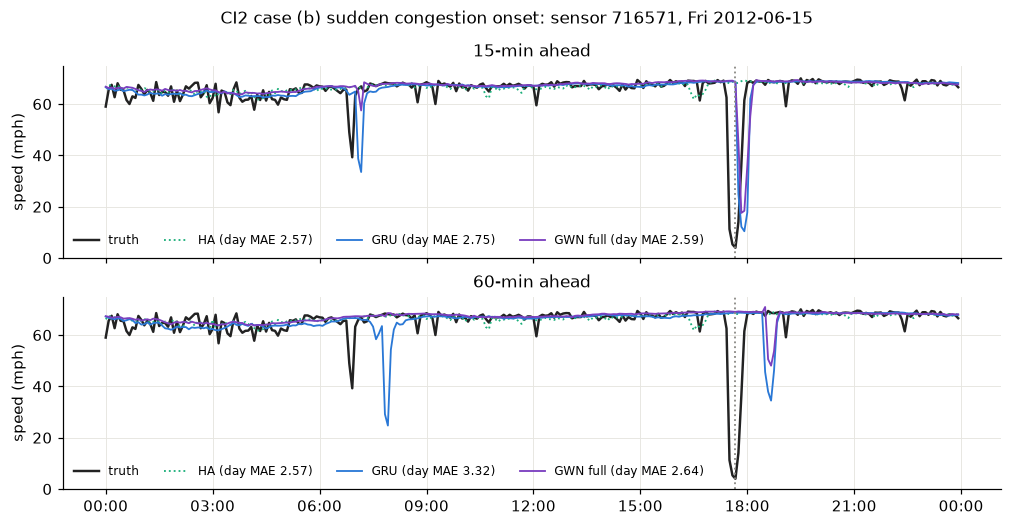

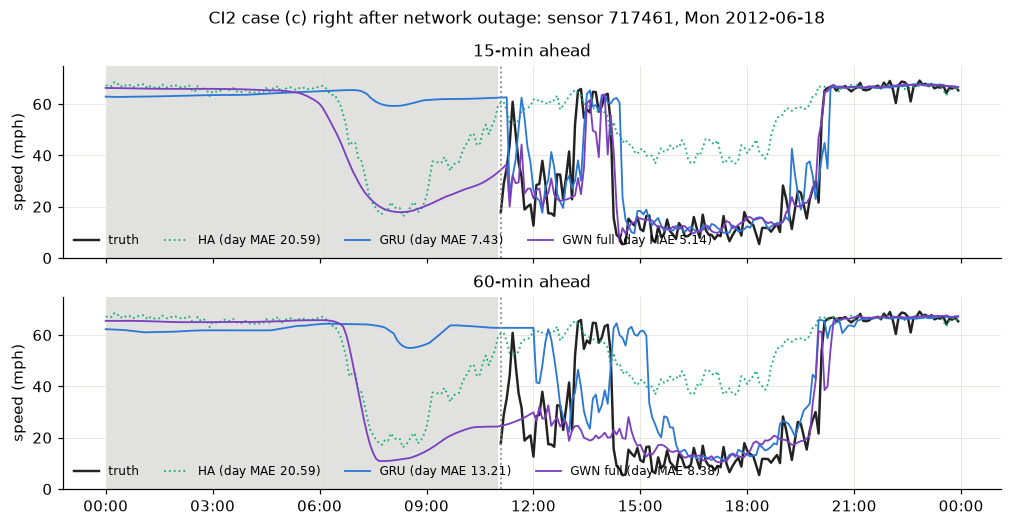

,case,sensor_id,date,HA MAE 15min,GRU MAE 15min,GWN full MAE 15min,HA MAE 60min,GRU MAE 60min,GWN full MAE 60min
0,(a) GRU does well,718076,2012-06-22 (Fri),1.66,1.31,1.27,1.66,1.36,1.33
1,(b) sudden congestion onset,716571,2012-06-15 (Fri),2.57,2.75,2.59,2.57,3.32,2.64
2,(c) right after network outage,717461,2012-06-18 (Mon),20.59,7.43,5.14,20.59,13.21,8.38


In [14]:
ts_day = ts.normalize()
allzero = (raw == 0).all(1)
def day_idx(d):
    return np.where(ts_day == d)[0]

def plot_day(n, day, title, fname, models=("HA", "GRU", "GWN full"), mark=None):
    ix = day_idx(day)
    t_ax = ts[ix]
    fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    row = {"sensor_id": sensor_ids[n], "date": f"{day:%Y-%m-%d (%a)}"}
    for ax, h in zip(axs, (3, 12)):
        tr = truth[ix, n]
        ax.plot(t_ax, tr, color=COL["truth"], lw=1.6, label="truth")
        for k in models:
            pr = pred_series[(k, h)][ix, n]
            e = float(np.nanmean(np.abs(pr - tr)))
            row[f"{k} MAE {h * 5}min"] = round(e, 2)
            ax.plot(t_ax, pr, ":" if k == "HA" else "-", color=COL[k], lw=1.2, label=f"{k} (day MAE {e:.2f})")
        if mark is not None:
            ax.axvline(mark, color=GRAY, ls=":", lw=1.2)
        # shade network-wide outages (every sensor missing)
        gone = allzero[ix]
        ax.fill_between(t_ax, 0, 75, where=gone, color=GRAY, alpha=0.25, lw=0)
        ax.set(ylabel="speed (mph)", title=f"{h * 5}-min ahead", ylim=(0, 75))
        ax.legend(loc="lower left", fontsize=8, ncol=4)
    axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    fig.suptitle(title, fontsize=11)
    save(fig, fname)
    return row

ci2_cases = pd.read_csv(CI2 / "figures" / "qualitative_cases.csv", dtype={"sensor_id": str})
rows = []
for (_, c), fname in zip(ci2_cases.iterrows(), ["Q1_ci2_good_sensor", "Q2_ci2_congestion_onset", "Q3_ci2_after_outage"]):
    day = pd.Timestamp(c["date"][:10])
    mark = pd.Timestamp(c["event_time"]) if isinstance(c["event_time"], str) else None
    row = plot_day(sid_to_idx[c["sensor_id"]], day, f"CI2 case {c['case']}: sensor {c['sensor_id']}, {day:%a %Y-%m-%d}", fname, mark=mark)
    # sanity: our GRU day MAE must be CI2's
    assert abs(row["GRU MAE 60min"] - c["GRU MAE 60min"]) < 0.011, (row, c)
    rows.append({"case": c["case"], **row})
q_ci2 = pd.DataFrame(rows)
display(q_ci2)
q_ci2.to_csv(fig_dir / "qualitative_ci2_cases.csv", index=False)
numbers["qualitative_ci2"] = q_ci2.to_dict("records")

**Takeaway.** On the easy day (a) the two models are the same (1.33 vs 1.36 mph at 60 min). On the congestion-onset day (b) GWN full is better over the day (2.64 vs 3.32) but, as the plot shows, it still misses the single sharpest drop; that moment comes back as case (f) below. The biggest change is day (c), right after the network outage, where the 60-min MAE falls from 13.21 to 8.38 mph.

## 7. Where Graph WaveNet still fails
### 7.1 Three new cases, picked by code
We look for GWN full's own worst moments on full test weekdays (sensor-days that are at least 90% observed):
* **(d)** the sensor-day with the highest GWN full 60-min MAE;
* **(e)** the sensor-day where GWN full is worse than the GRU by the widest margin at 60 min (the extension made it worse);
* **(f)** the single largest GWN full 60-min error, at a sensor not already used in (d) or (e).

17 full test weekdays: 2012-06-05 .. 2012-06-27


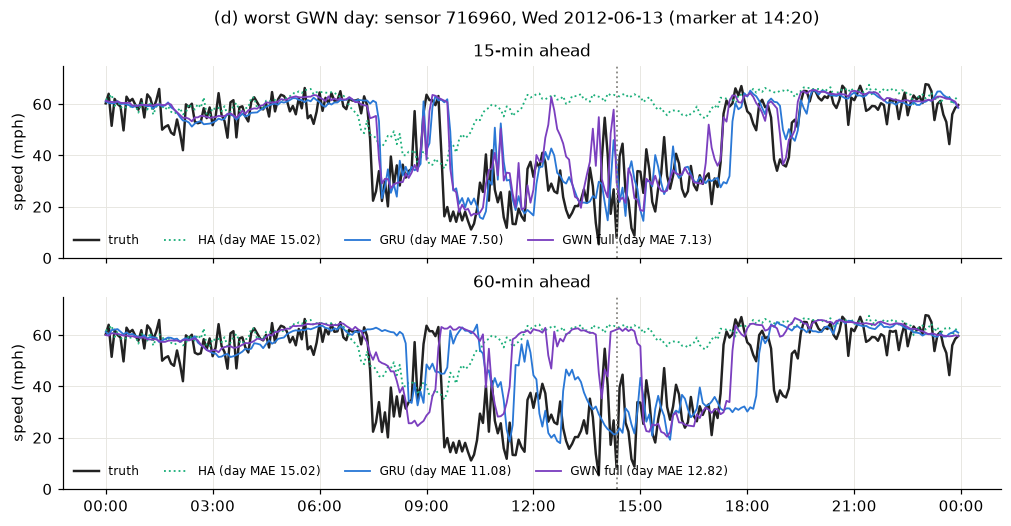

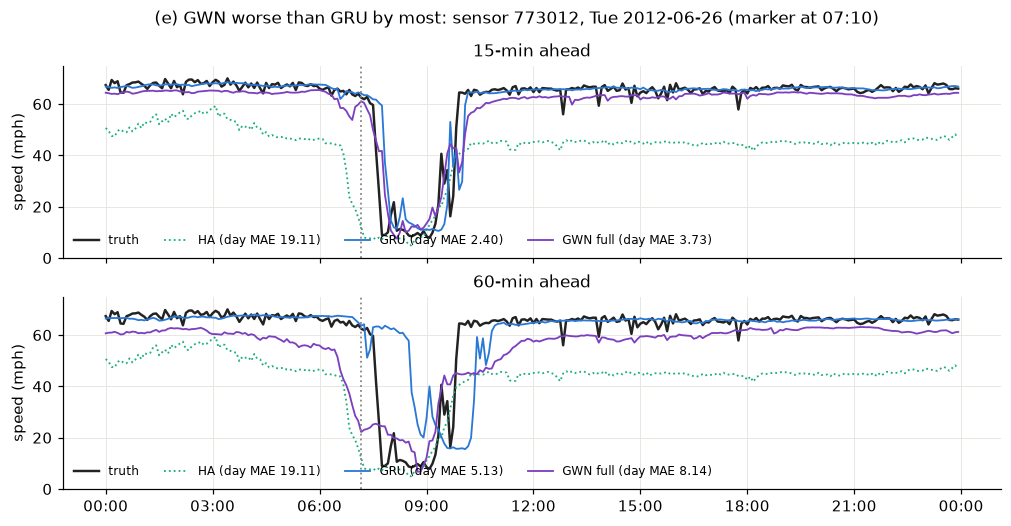

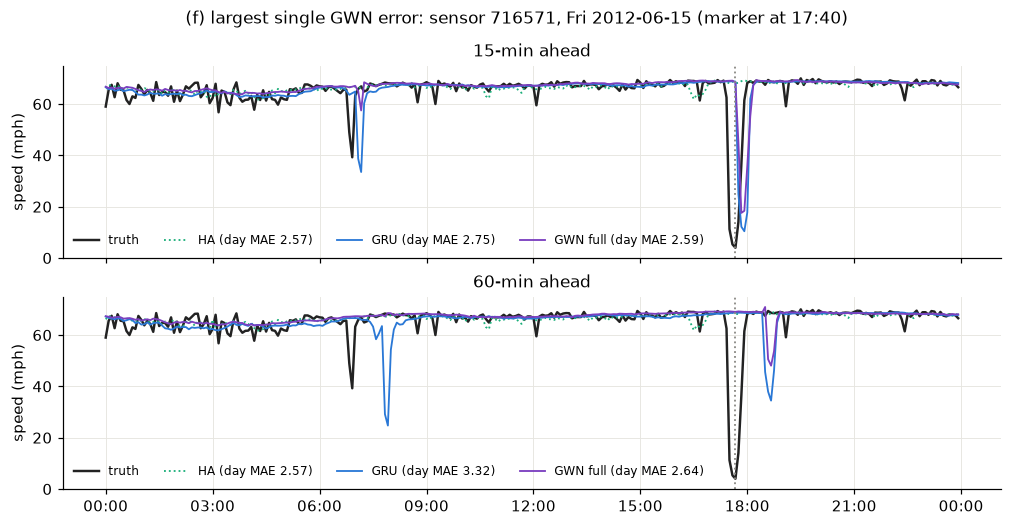

case,(d) worst GWN day,(e) GWN worse than GRU by most,(f) largest single GWN error
in-degree,3,1,1
out-degree,6,6,3
day observed,1.0,1.0,1.0
min speed,5.4,7.9,4.0
largest gap below HA (mph),57.5,15.1,64.1
sensor share <40 mph (test),0.199,0.079,0.002
event time,2012-06-13 14:20,2012-06-26 07:10,2012-06-15 17:40
truth / GWN / GRU at event,7.9 / 62.2 / 21.4,62.5 / 22.2 / 63.7,4.0 / 69.0 / 68.8
own input missing,0.0,0.0,0.0
own input min speed,15.7,65.4,61.4


In [15]:
covered = ~np.isnan(pred_series[("GWN full", 12)][:, 0])
days = [d for d in ts_day[s_te:e_te].unique() if d.dayofweek < 5 and covered[ts_day == d].all() and (ts_day == d).sum() == 288]
print(f"{len(days)} full test weekdays: {days[0].date()} .. {days[-1].date()}")

day_mae = {k: np.full((len(days), len(sensor_ids)), np.nan) for k in ["HA", "GRU", "GWN full"]}
observed_ok = np.zeros((len(days), len(sensor_ids)), bool)
for i, d in enumerate(days):
    ix = day_idx(d)
    observed_ok[i] = np.isfinite(truth[ix]).mean(0) >= 0.9
    for k in day_mae:
        day_mae[k][i] = np.nanmean(np.abs(pred_series[(k, 12)][ix] - truth[ix]), 0)

def pick(score, exclude=()):
    s = np.where(observed_ok, score, -np.inf)
    s[:, list(exclude)] = -np.inf
    i, n = np.unravel_index(np.argmax(s), s.shape)
    return int(i), int(n)

i_d, n_d = pick(day_mae["GWN full"])
i_e, n_e = pick(day_mae["GWN full"] - day_mae["GRU"], exclude=[n_d])

# (f): largest single 60-min error on a well-observed full weekday, at a new sensor
e60 = np.abs(pred_series[("GWN full", 12)] - truth)
valid = np.zeros(n_times, bool)
valid[np.concatenate([day_idx(d) for d in days])] = True
e60 = np.where(valid[:, None], e60, np.nan)
e60[:, [n_d, n_e]] = np.nan
for i, d in enumerate(days):
    e60[np.ix_(day_idx(d), ~observed_ok[i])] = np.nan
t_f, n_f = np.unravel_index(np.nanargmax(e60), e60.shape)
t_f, n_f = int(t_f), int(n_f)

def describe(case, n, day, t_event=None):
    ix = day_idx(day)
    tr = truth[ix, n]
    ha = pred_series[("HA", 12)][ix, n]
    nbrs = [j for j in np.where((adj[n] > 0.1) | (adj[:, n] > 0.1))[0] if j != n]
    info = {"case": case, "in-degree": int(in_deg[n]), "out-degree": int(out_deg[n]),
            "day observed": round(float(np.isfinite(tr).mean()), 3),
            "min speed": round(float(np.nanmin(tr)), 1),
            "largest gap below HA (mph)": round(float(np.nanmax(ha - tr)), 1),
            "sensor share <40 mph (test)": round(float(cong_share[n]), 3)}
    if t_event is not None:
        # the 12 input steps behind a 60-min forecast for t_event are t-23 .. t-12
        own_in = truth[t_event - 23:t_event - 11, n]
        nb_in = truth[t_event - 23:t_event - 11][:, nbrs]
        info["event time"] = f"{ts[t_event]:%Y-%m-%d %H:%M}"
        info["truth / GWN / GRU at event"] = (f"{truth[t_event, n]:.1f} / {pred_series[('GWN full', 12)][t_event, n]:.1f} / "
                                              f"{pred_series[('GRU', 12)][t_event, n]:.1f}")
        info["own input missing"] = round(float(np.isnan(own_in).mean()), 2)
        info["own input min speed"] = None if np.isnan(own_in).all() else round(float(np.nanmin(own_in)), 1)
        info["neighbour input min speed"] = None if np.isnan(nb_in).all() else round(float(np.nanmin(nb_in)), 1)
        info["neighbours <40 mph in input"] = int((np.nanmin(np.where(np.isnan(nb_in), 99, nb_in), 0) < 40).sum())
    return info

def worst_time(n, day):
    ix = day_idx(day)
    e = np.abs(pred_series[("GWN full", 12)][ix, n] - truth[ix, n])
    return int(ix[np.nanargmax(e)])

new_cases = [("(d) worst GWN day", n_d, days[i_d], worst_time(n_d, days[i_d])),
             ("(e) GWN worse than GRU by most", n_e, days[i_e], worst_time(n_e, days[i_e])),
             ("(f) largest single GWN error", n_f, ts_day[t_f], t_f)]
rows = []
for (case, n, day, t_event), fname in zip(new_cases, ["Q4_gwn_worst_day", "Q5_gwn_worse_than_gru", "Q6_gwn_largest_error"]):
    row = plot_day(n, day, f"{case}: sensor {sensor_ids[n]}, {day:%a %Y-%m-%d} (marker at {ts[t_event]:%H:%M})", fname, mark=ts[t_event])
    rows.append({**describe(case, n, day, t_event), **row})
q_new = pd.DataFrame(rows).set_index("case")
display(q_new.T)
q_new.to_csv(fig_dir / "qualitative_gwn_failures.csv")
numbers["qualitative_gwn_failures"] = q_new.reset_index().to_dict("records")

**Takeaway.** The three cases show three different failures.
* **(d) Sensor 716960, Wed 2012-06-13** (GWN 12.82 vs GRU 11.08 mph at 60 min): the sensor sits in congestion from mid-morning to late afternoon on a day when the historical average says 60 mph. GWN full's 60-min forecast keeps jumping back to about 62 mph, e.g. at 14:20 it predicts 62.2 when the truth is 7.9 (GRU 21.4). The GRU, which copies its own recent input, does better here.
* **(e) Sensor 773012, Tue 2012-06-26** (8.14 vs 5.13 mph): GWN full predicts the morning breakdown about half an hour too early (22.2 mph at 07:10 when the truth is still 62.5 and a neighbour is already at 31.2), and then stays about 5 mph too low for the rest of the day. This is a graph-induced false alarm: the neighbours' congestion is real, the timing at this sensor is wrong.
* **(f) Sensor 716571, Fri 2012-06-15 17:40**: the truth is 4.0 mph and both models predict about 69. The sensor is congested in only 0.2% of the test set and its own input was at 61 mph or more, so nothing in its history suggested a collapse. One neighbour was already slow (5.2 mph) and the model did not act on it.

### 7.2 What do Graph WaveNet's largest errors have in common?
We take the top 1% of GWN full's 60-min absolute errors and ask how often each condition holds, compared with all 60-min targets.

In [16]:
o12 = obs[:, 11]
e_w = err["GWN full"][:, 11]
thr = np.quantile(e_w[o12], 0.99)
top = o12 & (e_w >= thr)
y12 = y[:, 11]
ha12 = preds["HA"][:, 11]
x_last_missing = kmiss == 12
t12 = target_idx[:, 11]
# a sharp drop at this sensor ending within the hour before the target time (so mostly after the forecast was made)
recent_drop = np.zeros_like(o12)
dropped = np.nan_to_num(drop, nan=0) > 15
for back in range(0, 12):
    recent_drop |= dropped[t12 - back]
net_out = (kmiss == 12).mean(1) > 0.9
conditions = {
    "target is congested (<40 mph)": y12 < 40,
    "truth at least 20 mph below HA (unusual slowdown)": (ha12 - y12) >= 20,
    "truth at least 20 mph above HA (unusual free flow)": (y12 - ha12) >= 20,
    "sharp drop (>15 mph / 30 min) in the hour before the target": recent_drop,
    "all 12 own input steps missing": x_last_missing,
    "network-wide outage in the input (>90% sensors missing)": np.broadcast_to(net_out[:, None], o12.shape),
    "GWN over-predicts (misses a slowdown)": (preds["GWN full"][:, 11] - y12) > 0,
    "GRU error is also in its own top 1%": err["GRU"][:, 11] >= np.quantile(err["GRU"][:, 11][o12], 0.99),
    "weekend": np.broadcast_to(wkend[:, 11][:, None], o12.shape),
}
rows = []
for label, c in conditions.items():
    rows.append({"condition": label, "share of top 1% GWN errors": c[top].mean(), "share of all targets": c[o12].mean()})
topc = pd.DataFrame(rows).set_index("condition")
topc["lift"] = topc["share of top 1% GWN errors"] / topc["share of all targets"]
display(topc.round(3))
topc.round(3).to_csv(fig_dir / "gwn_top_errors.csv")
numbers["gwn_top1pct"] = {"threshold_mph": round(float(thr), 1), "n": int(top.sum()),
                          "share_of_abs_error": round(float(e_w[top].sum() / e_w[o12].sum()), 3),
                          "table": topc.round(3).reset_index().to_dict("records")}
print(f"top 1% = errors above {thr:.1f} mph ({top.sum():,} targets); they carry {e_w[top].sum() / e_w[o12].sum():.1%} of GWN full's 60-min absolute error")

# sharp drops: does a slowed-down neighbour in the input help?
t_made = t12 - 12                                # last input step of the window behind each 60-min target
miss_drop = o12 & recent_drop & (y12 < 40)
slow = np.nan_to_num(truth, nan=99) < 40
nbr_mask = ((adj > 0.1) | (adj.T > 0.1)) & ~np.eye(len(sensor_ids), dtype=bool)
nbr_slow_in = np.zeros_like(o12)
own_slow_in = np.zeros_like(o12)
for back in range(12):
    s = slow[t_made - back]                      # (windows, sensors)
    own_slow_in |= s
    nbr_slow_in |= (s.astype(np.float32) @ nbr_mask.T.astype(np.float32)) > 0
rows = []
for label, c in [("own input already slow", own_slow_in),
                 ("own input fast, a graph neighbour already slow", ~own_slow_in & nbr_slow_in),
                 ("own input fast, no neighbour slow (nothing to see)", ~own_slow_in & ~nbr_slow_in)]:
    sel2 = miss_drop & c
    rows.append({"congested target after a sharp drop, and": label, "targets": int(sel2.sum()),
                 **{k: float(err[k][:, 11][sel2].mean()) for k in ["HA", "GRU", "GWN no-graph", "GWN full"]}})
vis = pd.DataFrame(rows).set_index("congested target after a sharp drop, and")
vis["graph effect (full - no-graph)"] = vis["GWN full"] - vis["GWN no-graph"]
display(vis.round(2))
vis.round(3).to_csv(fig_dir / "gwn_drop_visibility.csv")
numbers["drop_visibility"] = vis.round(2).reset_index().to_dict("records")

,share of top 1% GWN errors,share of all targets,lift
condition,,,
target is congested (<40 mph),0.697,0.124,5.636
truth at least 20 mph below HA (unusual slowdown),0.628,0.031,20.564
truth at least 20 mph above HA (unusual free flow),0.143,0.010,14.143
sharp drop (>15 mph / 30 min) in the hour before the target,0.670,0.117,5.742
all 12 own input steps missing,0.089,0.015,5.989
network-wide outage in the input (>90% sensors missing),0.081,0.013,6.434
GWN over-predicts (misses a slowdown),0.697,0.512,1.361
GRU error is also in its own top 1%,0.435,0.010,43.470
weekend,0.229,0.205,1.118


top 1% = errors above 35.5 mph (12,426 targets); they carry 12.4% of GWN full's 60-min absolute error


,targets,HA,GRU,GWN no-graph,GWN full,graph effect (full - no-graph)
"congested target after a sharp drop, and",,,,,,
own input already slow,41786,15.28,13.99,14.07,10.84,-3.23
"own input fast, a graph neighbour already slow",24569,17.79,31.73,31.65,18.02,-13.63
"own input fast, no neighbour slow (nothing to see)",9039,14.83,33.85,33.49,17.07,-16.42


**Takeaway.** The top 1% of GWN full's 60-min errors (above 35.5 mph) carry 12.4% of its total error. Of these, 70% are congested targets (12% of all targets), 63% are slowdowns at least 20 mph below the historical average (3% of all targets, a 21-fold lift), 67% follow a sharp drop, and 70% are over-predictions, i.e. a missed slowdown. 43% of them are also among the GRU's top 1%, so a large part of the hard cases is shared. The second table shows that the graph helps most where the sensor's own input still looks fast (-13.6 and -16.4 mph), but those cases remain the worst ones (17-18 mph against 10.8 when the sensor's own input is already slow). We expected the graph to help only when a direct neighbour was already slow; it helps just as much when none was, so the simple "one-hop neighbour drops first" picture from CI2 is too narrow. The model can reach much further than one hop (8 graph layers of order 2, plus the adaptive adjacency).

### 7.3 Do Graph WaveNet's worst sensors have few graph neighbours?

,sensor_id,GWN full 60,GRU 60,HA,share <40 mph,test missing rate,in-degree,out-degree
rank,,,,,,,,
1,717462,7.58,10.08,11.75,0.40,0.10,14,13
2,716960,7.32,8.03,8.44,0.20,0.14,3,6
3,717466,7.30,9.15,11.95,0.32,0.10,14,11
4,717468,7.27,9.14,12.76,0.28,0.10,14,14
5,716958,6.97,8.08,8.04,0.25,0.14,5,8
6,718045,6.93,9.91,7.52,0.30,0.14,6,14
7,773939,6.92,9.53,9.91,0.25,0.10,3,3
8,717461,6.85,9.81,10.01,0.48,0.20,17,11
9,717472,6.48,8.65,12.36,0.25,0.13,10,12


,GWN worst 10,all sensors
in-degree,11.5,7.0
out-degree,11.5,7.0
degree,23.5,15.0


,sensors,GRU 60,GWN no-graph 60,GWN full 60,share <40 mph,graph effect (full - no-graph)
lowest-degree quarter,56,4.115,4.092,3.379,0.080,-0.713
highest-degree quarter,52,5.377,5.342,3.942,0.221,-1.400


Spearman with total degree: {'GWN full 60': 0.14, 'graph effect': -0.4, 'degree': 1.0, 'in-degree': 0.86, 'out-degree': 0.84, 'share <40 mph': 0.34}
9 of GWN's worst 10 were also in CI2's worst 10: ['716958', '717458', '717461', '717462', '717466', '717468', '717472', '718045', '773939']


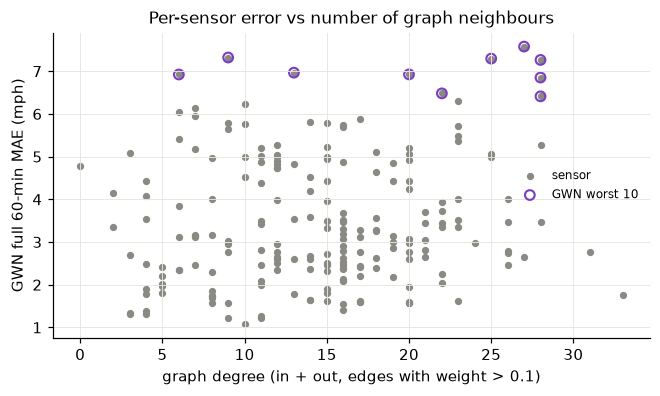

In [17]:
sens["degree"] = sens["in-degree"] + sens["out-degree"]
worst_gwn = sens.sort_values("GWN full 60", ascending=False).head(10)
display(worst_gwn[["sensor_id", "GWN full 60", "GRU 60", "HA", "share <40 mph", "test missing rate", "in-degree", "out-degree"]]
        .round(2).assign(rank=range(1, 11)).set_index("rank"))
worst_gwn.round(3).to_csv(fig_dir / "gwn_worst10.csv", index=False)
overlap = sorted(set(worst_gwn.sensor_id) & set(ci2_worst_ids))
deg_tab = pd.DataFrame({
    "GWN worst 10": worst_gwn[["in-degree", "out-degree", "degree"]].median(),
    "all sensors": sens[["in-degree", "out-degree", "degree"]].median(),
})
display(deg_tab)
low_deg = sens.degree <= sens.degree.quantile(0.25)
high_deg = sens.degree >= sens.degree.quantile(0.75)
deg_groups = pd.DataFrame({
    "sensors": [int(low_deg.sum()), int(high_deg.sum())],
    "GRU 60": [sens[low_deg]["GRU 60"].mean(), sens[high_deg]["GRU 60"].mean()],
    "GWN no-graph 60": [sens[low_deg]["GWN no-graph 60"].mean(), sens[high_deg]["GWN no-graph 60"].mean()],
    "GWN full 60": [sens[low_deg]["GWN full 60"].mean(), sens[high_deg]["GWN full 60"].mean()],
    "share <40 mph": [sens[low_deg]["share <40 mph"].mean(), sens[high_deg]["share <40 mph"].mean()],
}, index=["lowest-degree quarter", "highest-degree quarter"])
deg_groups["graph effect (full - no-graph)"] = deg_groups["GWN full 60"] - deg_groups["GWN no-graph 60"]
display(deg_groups.round(3))
sens["graph effect"] = sens["GWN full 60"] - sens["GWN no-graph 60"]
rho_deg = sens[["GWN full 60", "graph effect", "degree", "in-degree", "out-degree", "share <40 mph"]].corr(method="spearman")
print("Spearman with total degree:", rho_deg["degree"].round(2).to_dict())
print(f"{len(overlap)} of GWN's worst 10 were also in CI2's worst 10: {overlap}")
numbers["gwn_worst10"] = {
    "table": worst_gwn[["sensor_id", "GWN full 60", "GRU 60", "HA", "share <40 mph", "test missing rate", "in-degree", "out-degree"]].round(2).to_dict("records"),
    "overlap_with_ci2_worst10": overlap,
    "median_degree": deg_tab.to_dict(),
    "degree_groups": deg_groups.round(3).reset_index().to_dict("records"),
    "spearman_with_degree": rho_deg["degree"].round(2).to_dict(),
}

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(sens.degree, sens["GWN full 60"], s=14, color=GRAY, label="sensor")
ax.scatter(worst_gwn.degree, worst_gwn["GWN full 60"], s=40, facecolor="none", edgecolor=C4, lw=1.4, label="GWN worst 10")
ax.set(xlabel="graph degree (in + out, edges with weight > 0.1)", ylabel="GWN full 60-min MAE (mph)",
       title="Per-sensor error vs number of graph neighbours")
ax.legend(fontsize=8)
save(fig, "FA6_error_vs_degree")

**Takeaway.** No: GWN full's worst sensors are well connected. Their median degree is 23.5 against 15 for all sensors, and across sensors the 60-min MAE barely correlates with degree (Spearman 0.14). Nine of its ten worst sensors were already in the GRU's worst ten. What they share is congestion, not isolation (25-50% of their targets are below 40 mph). Degree does matter for the size of the gain: the graph is worth 1.40 mph in the highest-degree quarter and 0.71 mph in the lowest (Spearman -0.40 between degree and the graph effect), although high-degree sensors are also the more congested ones (22% vs 8%), so the two explanations cannot be separated here.

### 7.4 Error by test day (drift or unusual days in June?)

,weekday,observed,HA,GRU,GWN full,GRU - GWN full
day,,,,,,
2012-06-04,Mon,0.94,4.64,5.31,3.88,1.43
2012-06-05,Tue,0.91,3.85,4.55,3.25,1.30
2012-06-06,Wed,0.98,4.43,4.58,3.44,1.13
2012-06-07,Thu,0.94,4.50,5.10,3.64,1.46
2012-06-08,Fri,0.98,4.19,4.79,3.66,1.13
2012-06-09,Sat,0.58,3.76,3.87,3.28,0.60
2012-06-10,Sun,0.90,2.57,2.50,2.34,0.17
2012-06-11,Mon,0.99,3.85,4.15,3.29,0.86
2012-06-12,Tue,0.92,4.31,4.91,3.60,1.32


{'worst_day_gwn': '2012-06-17', 'worst_day_gwn_mae': 5.23, 'days_gwn_better': 24, 'days': 24, 'gwn_first_half': 3.48, 'gwn_second_half': 3.63, 'ha_first_half': 4.19, 'ha_second_half': 4.36, 'days_gwn_worse_than_ha': ['2012-06-16']}


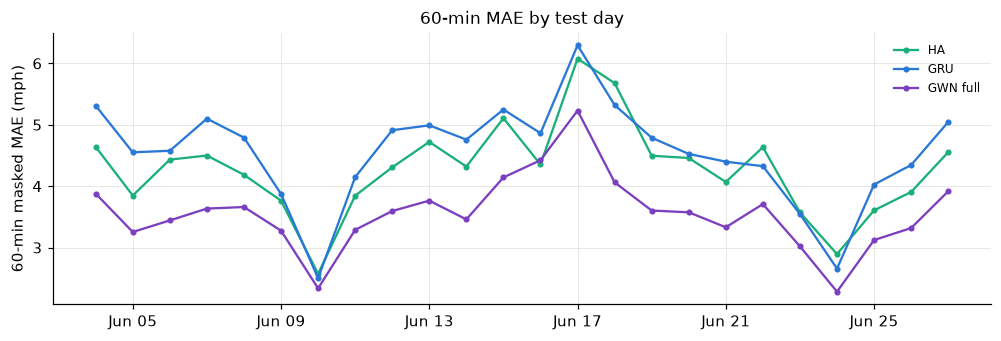

In [18]:
day_of = ts_day[target_idx[:, 11]]
rows = []
for d in pd.DatetimeIndex(day_of).unique():
    w = np.asarray(day_of == d)
    o = obs[w, 11]
    if o.sum() == 0:
        continue
    rows.append({"day": d, "weekday": d.day_name()[:3], "observed": o.mean(),
                 **{k: float(err[k][w, 11][o].mean()) for k in ["HA", "GRU", "GWN full"]}})
by_day = pd.DataFrame(rows).set_index("day")
by_day["GRU - GWN full"] = by_day["GRU"] - by_day["GWN full"]
display(by_day.round(2))
by_day.round(3).to_csv(fig_dir / "mae_by_day.csv")
first_half, second_half = by_day.iloc[:len(by_day) // 2], by_day.iloc[len(by_day) // 2:]
numbers["by_day"] = {
    "worst_day_gwn": f"{by_day['GWN full'].idxmax():%Y-%m-%d}", "worst_day_gwn_mae": round(float(by_day["GWN full"].max()), 2),
    "days_gwn_better": int((by_day["GRU - GWN full"] > 0).sum()), "days": int(len(by_day)),
    "gwn_first_half": round(float(first_half["GWN full"].mean()), 2), "gwn_second_half": round(float(second_half["GWN full"].mean()), 2),
    "ha_first_half": round(float(first_half["HA"].mean()), 2), "ha_second_half": round(float(second_half["HA"].mean()), 2),
    "days_gwn_worse_than_ha": [f"{d:%Y-%m-%d}" for d in by_day.index[by_day["GWN full"] > by_day["HA"]]],
}
print(numbers["by_day"])

fig, ax = plt.subplots(figsize=(11, 3.2))
for k in ["HA", "GRU", "GWN full"]:
    ax.plot(by_day.index, by_day[k], LS[k], marker="o", ms=3, color=COL[k], label=k)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set(ylabel="60-min masked MAE (mph)", title="60-min MAE by test day")
ax.legend(fontsize=8)
save(fig, "FA7_mae_by_day")

**Takeaway.** GWN full is better than the GRU on all 24 test days, so the result does not depend on a few good days. Its worst day is Sunday 2012-06-17 (5.23 mph), when only 25% of the targets were observed because of the network outage, and on Saturday 2012-06-16 it is slightly worse than the historical average (4.42 vs 4.35). Its error is a little higher in the second half of the test period (3.63 vs 3.48), but the historical average moves the same way (4.36 vs 4.19), so this looks like harder days, not drift.

## 8. What did the adaptive adjacency learn?
The adaptive adjacency is `softmax(relu(E1 @ E2))` over two learned 207 x 10 embedding tables. Row *i* says how much sensor *i*'s graph convolution reads from every other sensor. We compare it with the road graph (`adj_METR-LA.pkl`).

,value
mass_on_self,0.007
mass_on_road_edges,0.064
mass_on_non_edges,0.930
road_edge_share_of_pairs,0.061
strong_edges,227.000
strong_edges_on_road_graph,0.070
strong_edges_median_km,10.231
road_edges_median_km,1.684
all_pairs_median_km,10.305
strong_edges_beyond_10km,0.520


,sensor i (reads),sensor j (from),weight,distance (km),road edge i->j,road edge j->i
0,769405,716328,0.158,10.679,0.000,0.000
1,773023,716331,0.137,2.222,0.196,0.149
2,737529,769405,0.132,14.567,0.000,0.000
3,767541,716331,0.128,5.605,0.000,0.000
4,771667,716571,0.120,21.031,0.000,0.000
5,717570,771667,0.106,14.561,0.000,0.000
6,716328,718204,0.103,10.594,0.000,0.000
7,767542,771667,0.103,4.828,0.000,0.000
8,716941,717450,0.103,5.785,0.000,0.000
9,717582,771673,0.102,9.228,0.000,0.000


sensors most read from by others (column sums): {'716328': 1.809999942779541, '717446': 1.7699999809265137, '717450': 1.7400000095367432, '771667': 1.7300000190734863, '716331': 1.659999966621399}


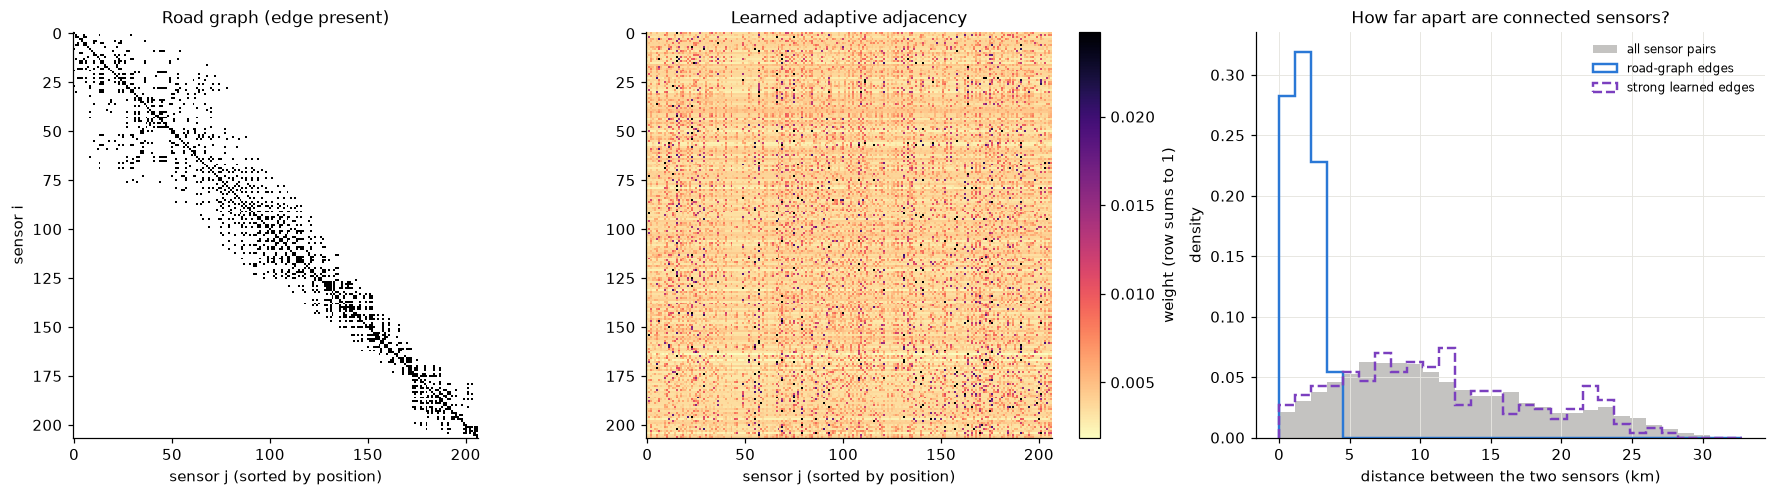

In [19]:
ckpt = torch.load(RUNS_DIR / FULL_RUN / "best.pt", map_location="cpu", weights_only=False)
e1 = ckpt["model"]["nodevec1"].numpy()
e2 = ckpt["model"]["nodevec2"].numpy()
logits = np.maximum(e1 @ e2, 0)
adp = np.exp(logits - logits.max(1, keepdims=True))
adp = adp / adp.sum(1, keepdims=True)

N = len(sensor_ids)
eye = np.eye(N, dtype=bool)
road = ((adj > 0) | (adj.T > 0)) & ~eye
lat, lon = np.radians(loc.latitude.to_numpy()), np.radians(loc.longitude.to_numpy())
a = np.sin((lat[:, None] - lat[None]) / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None]) * np.sin((lon[:, None] - lon[None]) / 2) ** 2
dist_km = 2 * 6371 * np.arcsin(np.sqrt(a))

uniform = 1 / N
strong = (adp > 5 * uniform) & ~eye                 # edges with at least 5x the weight of a uniform row
eff_n = np.exp(-(adp * np.log(adp + 1e-12)).sum(1))  # effective number of sensors each row attends to
adp_stats = {
    "mass_on_self": float(np.trace(adp) / N),
    "mass_on_road_edges": float(adp[road].sum() / N),
    "mass_on_non_edges": float(adp[~road & ~eye].sum() / N),
    "road_edge_share_of_pairs": float(road.sum() / (N * N)),
    "strong_edges": int(strong.sum()),
    "strong_edges_on_road_graph": float(road[strong].mean()) if strong.sum() else float("nan"),
    "strong_edges_median_km": float(np.nanmedian(dist_km[strong])) if strong.sum() else float("nan"),
    "road_edges_median_km": float(np.nanmedian(dist_km[road])),
    "all_pairs_median_km": float(np.nanmedian(dist_km[~eye])),
    "strong_edges_beyond_10km": float((dist_km[strong] > 10).mean()) if strong.sum() else float("nan"),
    "effective_neighbours_median": float(np.median(eff_n)),
    "rows_nearly_uniform": int((eff_n > 0.9 * N).sum()),
    "top_receivers_share_of_mass": float(np.sort(adp.sum(0))[::-1][:10].sum() / N),
}
display(pd.Series(adp_stats).round(3).to_frame("value"))
numbers["adaptive_adj"] = {k: round(v, 3) for k, v in adp_stats.items()}

off = np.where(eye, -1, adp)
order = np.argsort(off, axis=None)[::-1][:15]
rows = []
for i, j in zip(*np.unravel_index(order, off.shape)):
    rows.append({"sensor i (reads)": sensor_ids[i], "sensor j (from)": sensor_ids[j], "weight": adp[i, j],
                 "distance (km)": dist_km[i, j], "road edge i->j": float(adj[i, j]), "road edge j->i": float(adj[j, i])})
top_edges = pd.DataFrame(rows)
display(top_edges.round(3))
top_edges.round(3).to_csv(fig_dir / "adaptive_top_edges.csv", index=False)
numbers["adaptive_adj"]["top15_on_road_graph"] = int(((top_edges["road edge i->j"] > 0) | (top_edges["road edge j->i"] > 0)).sum())
numbers["adaptive_adj"]["top15_median_km"] = round(float(top_edges["distance (km)"].median()), 2)
hubs = pd.Series(adp.sum(0) - np.diag(adp), index=sensor_ids).sort_values(ascending=False).head(5)
print("sensors most read from by others (column sums):", hubs.round(2).to_dict())
numbers["adaptive_adj"]["top_hubs"] = hubs.round(2).to_dict()

# order sensors along the main spatial direction so nearby sensors sit next to each other
xy = np.c_[loc.longitude.to_numpy(), loc.latitude.to_numpy()]
xy = np.nan_to_num(xy - np.nanmean(xy, 0))
order_sp = np.argsort(xy @ np.linalg.svd(xy, full_matrices=False)[2][0])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
axs[0].imshow((adj[np.ix_(order_sp, order_sp)] > 0), cmap="Greys", interpolation="nearest")
axs[0].set(title="Road graph (edge present)", xlabel="sensor j (sorted by position)", ylabel="sensor i")
im = axs[1].imshow(adp[np.ix_(order_sp, order_sp)], cmap="magma_r", vmax=np.quantile(adp, 0.995), interpolation="nearest")
axs[1].set(title="Learned adaptive adjacency", xlabel="sensor j (sorted by position)")
plt.colorbar(im, ax=axs[1], fraction=0.046, label="weight (row sums to 1)")
for ax in axs[:2]:
    ax.grid(False)
bins_km = np.linspace(0, np.nanmax(dist_km), 30)
axs[2].hist(dist_km[~eye], bins=bins_km, density=True, color=GRAY, alpha=0.5, label="all sensor pairs")
axs[2].hist(dist_km[road], bins=bins_km, density=True, histtype="step", color=C1, lw=1.6, label="road-graph edges")
if strong.sum():
    axs[2].hist(dist_km[strong], bins=bins_km, density=True, histtype="step", color=C4, lw=1.6, ls="--", label="strong learned edges")
axs[2].set(xlabel="distance between the two sensors (km)", ylabel="density", title="How far apart are connected sensors?")
axs[2].legend(fontsize=8)
save(fig, "A1_adaptive_adjacency")

**Takeaway.** The adaptive adjacency did not rediscover the road graph. It is close to uniform: the median row spreads its weight over the equivalent of 183 of the 207 sensors, and 93.0% of the weight sits on pairs that are not road-graph edges (such pairs are 93.9% of all pairs). Of the 227 strongest learned edges only 7% are road edges, and their median length is 10.2 km, the same as for random sensor pairs (10.3 km) and far from the 1.7 km of road edges. So what it adds is mostly a network-wide average plus a few long-range links between sensors that behave alike. We did not train the fixed-only and adaptive-only models, so we cannot say how much this term contributes to the 0.55 mph graph gain.

## 9. Summary: what got better, what got worse, and why
**Better.** GWN full beats the GRU at every horizon (MAE 2.70 / 3.07 / 3.48 vs 2.99 / 3.60 / 4.46 mph), at 99.5-100% of sensors and on all 24 test days. The CI2 failures all shrink: congested 60-min MAE 14.46 to 9.70 (now below persistence), median drop lag 12 to 4 steps, no weekday hour worse than the historical average, and the day after the outage 13.21 to 8.38.

**Why.** 97% of the gain comes from the graph convolutions; the same network without them performs like the GRU (3.576 vs 3.593 mph over all horizons).

**Worse.** Training takes 3.9 times as long (70.5 vs 18.2 min), inference 2.8 times (10.7 vs 3.8 s), and the model has 5.9 times the parameters. GWN full ignores more short drops than the GRU (48% vs 40% at 60 min), raises early false alarms from neighbours' congestion (case e), reverts to free-flow speeds during long unusual congestion (case d), and is slightly worse than its own no-graph version when the whole network is down (7.74 vs 7.33).

**Still failing.** Unusual slowdowns that are not yet visible in the sensor's own input: 17-18 mph error at 60 min, and they dominate the top 1% of errors. The worst sensors are the same congested ones as in CI2, and they are not poorly connected.

In [20]:
(fig_dir / "ci3_numbers.json").write_text(json.dumps(numbers, indent=1, default=str))
print("wrote", fig_dir / "ci3_numbers.json")

wrote /Users/mikekwon/Documents/georgetownFall26/DSAN6600/Deep-Learning-6600/Project_check_in_3/figures/ci3_numbers.json
